# Diagnoza obiektów AnnData

Notebook do przeglądu wyników importu GEO zapisanych jako `data/anndata/<GSE>/<GSM>.h5ad`. Wczytuje wyłącznie istniejące pliki, pokazuje raport importu, przykładowe `obs`/`var`, kompletność pól i mały wycinek `X`. Niczego nie zapisuje ani nie modyfikuje. `cell_type` pozostaje puste do czasu osobnej anotacji.


In [2]:
from pathlib import Path
import json
import warnings

import anndata as ad
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse

# Działa zarówno po uruchomieniu z katalogu projektu, jak i z notebooks/.
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_ROOT = PROJECT_ROOT / 'data' / 'anndata'
GSE_IDS = ['GSE150115', 'GSE162335', 'GSE346721']
MAX_PREVIEW_CELLS = 20
MAX_PREVIEW_FEATURES = 30

if not DATA_ROOT.exists():
    raise FileNotFoundError(f'Nie znaleziono katalogu wyników: {DATA_ROOT}')
print(f'Katalog wyników: {DATA_ROOT}')


Katalog wyników: /home/piotr_zawierucha/hermes-work/data/anndata


## Raporty importu

Zbiorcze statusy pokazują, co Hermes zapisał dla każdej serii. Brak raportu lub pliku `.h5ad` oznacza, że wynik nie został jeszcze zapisany w tej lokalizacji.


In [3]:
reports = {}
report_rows = []
for gse in GSE_IDS:
    report_path = DATA_ROOT / gse / 'anndata_import_report.json'
    if report_path.exists():
        report = json.loads(report_path.read_text())
        reports[gse] = report
        report_rows.append({
            'GSE': gse,
            'status': report.get('status', 'unknown'),
            'included': report.get('included_sample_count'),
            'succeeded': report.get('success_count'),
            'unresolved': report.get('unresolved_count'),
            'report': str(report_path.relative_to(PROJECT_ROOT)),
        })
    else:
        report_rows.append({'GSE': gse, 'status': 'no report', 'included': None, 'succeeded': None, 'unresolved': None, 'report': None})

display(pd.DataFrame(report_rows))


,GSE,status,included,succeeded,unresolved,report
0,GSE150115,success,None,None,None,data/anndata/GSE150115/anndata_import_report.json
1,GSE162335,success,None,None,None,data/anndata/GSE162335/anndata_import_report.json
2,GSE346721,success,None,None,None,data/anndata/GSE346721/anndata_import_report.json


## Wczytanie dostępnych obiektów

Każdy GSM jest osobnym obiektem. Błędy pojedynczych plików są pokazane w tabeli i nie przerywają wczytywania pozostałych.


In [4]:
objects = {}
load_errors = []
for gse in GSE_IDS:
    for path in sorted((DATA_ROOT / gse).glob('*.h5ad')):
        try:
            objects[(gse, path.stem)] = ad.read_h5ad(path)
        except Exception as exc:
            load_errors.append({'GSE': gse, 'GSM/file': path.name, 'error': f'{type(exc).__name__}: {exc}'})

print(f'Wczytane obiekty: {len(objects)}')
if load_errors:
    display(pd.DataFrame(load_errors))
if not objects:
    print('Nie znaleziono jeszcze żadnych plików .h5ad. Uruchom import w Hermesie, a potem wykonaj ponownie komórki.')


Wczytane obiekty: 66


## Kształt, reprezentacja `X` i kompletność metadanych

Kompletność to liczba wartości niepustych i udział braków w każdej kolumnie. Wykres pokazuje udział niepustych wartości w `obs`; puste pola nie są uzupełniane automatycznie.


,GSE,GSM/file,cells,features,X storage,X format,X dtype,counts layer,matrix_semantics,obs index unique,var index unique
0,GSE150115,GSM4523789,4000,25223,sparse,csr,float32,True,raw counts,True,True
1,GSE150115,GSM4523790,4000,24231,sparse,csr,float32,True,raw counts,True,True
2,GSE150115,GSM4523791,4000,26983,sparse,csr,float32,True,raw counts,True,True
3,GSE150115,GSM4523792,10000,31840,sparse,csr,float32,True,raw counts,True,True
4,GSE150115,GSM4523793,10000,32263,sparse,csr,float32,True,raw counts,True,True
...,...,...,...,...,...,...,...,...,...,...,...
61,GSE346721,GSM10039398,5290,36601,sparse,csr,float32,False,unknown,True,True
62,GSE346721,GSM10039399,5978,36601,sparse,csr,float32,False,unknown,True,True
63,GSE346721,GSM10039400,6699,36601,sparse,csr,float32,False,unknown,True,True
64,GSE346721,GSM10039401,6782,36601,sparse,csr,float32,False,unknown,True,True


Kompletność pól obs:


,GSE,GSM/file,axis,field,non_null,missing,non_null_pct
0,GSE150115,GSM4523789,obs,sample_id,4000,0,100.0
1,GSE150115,GSM4523789,obs,source_barcode,4000,0,100.0
2,GSE150115,GSM4523789,obs,donor_id,0,4000,0.0
3,GSE150115,GSM4523789,obs,organism,4000,0,100.0
4,GSE150115,GSM4523789,obs,tissue,4000,0,100.0
...,...,...,...,...,...,...,...
985,GSE346721,GSM10039402,obs,timepoint,0,9632,0.0
986,GSE346721,GSM10039402,obs,source_accession,9632,0,100.0
987,GSE346721,GSM10039402,obs,n_counts,0,9632,0.0
988,GSE346721,GSM10039402,obs,n_features,0,9632,0.0


Kompletność pól var:


,GSE,GSM/file,axis,field,non_null,missing,non_null_pct
0,GSE150115,GSM4523789,var,feature_name,25223,0,100.0
1,GSE150115,GSM4523789,var,feature_type,0,25223,0.0
2,GSE150115,GSM4523789,var,genome_build,25223,0,100.0
3,GSE150115,GSM4523790,var,feature_name,24231,0,100.0
4,GSE150115,GSM4523790,var,feature_type,0,24231,0.0
...,...,...,...,...,...,...,...
193,GSE346721,GSM10039401,var,feature_type,36601,0,100.0
194,GSE346721,GSM10039401,var,genome_build,0,36601,0.0
195,GSE346721,GSM10039402,var,feature_name,36601,0,100.0
196,GSE346721,GSM10039402,var,feature_type,36601,0,100.0


/tmp/ipykernel_99026/1852781860.py:35: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


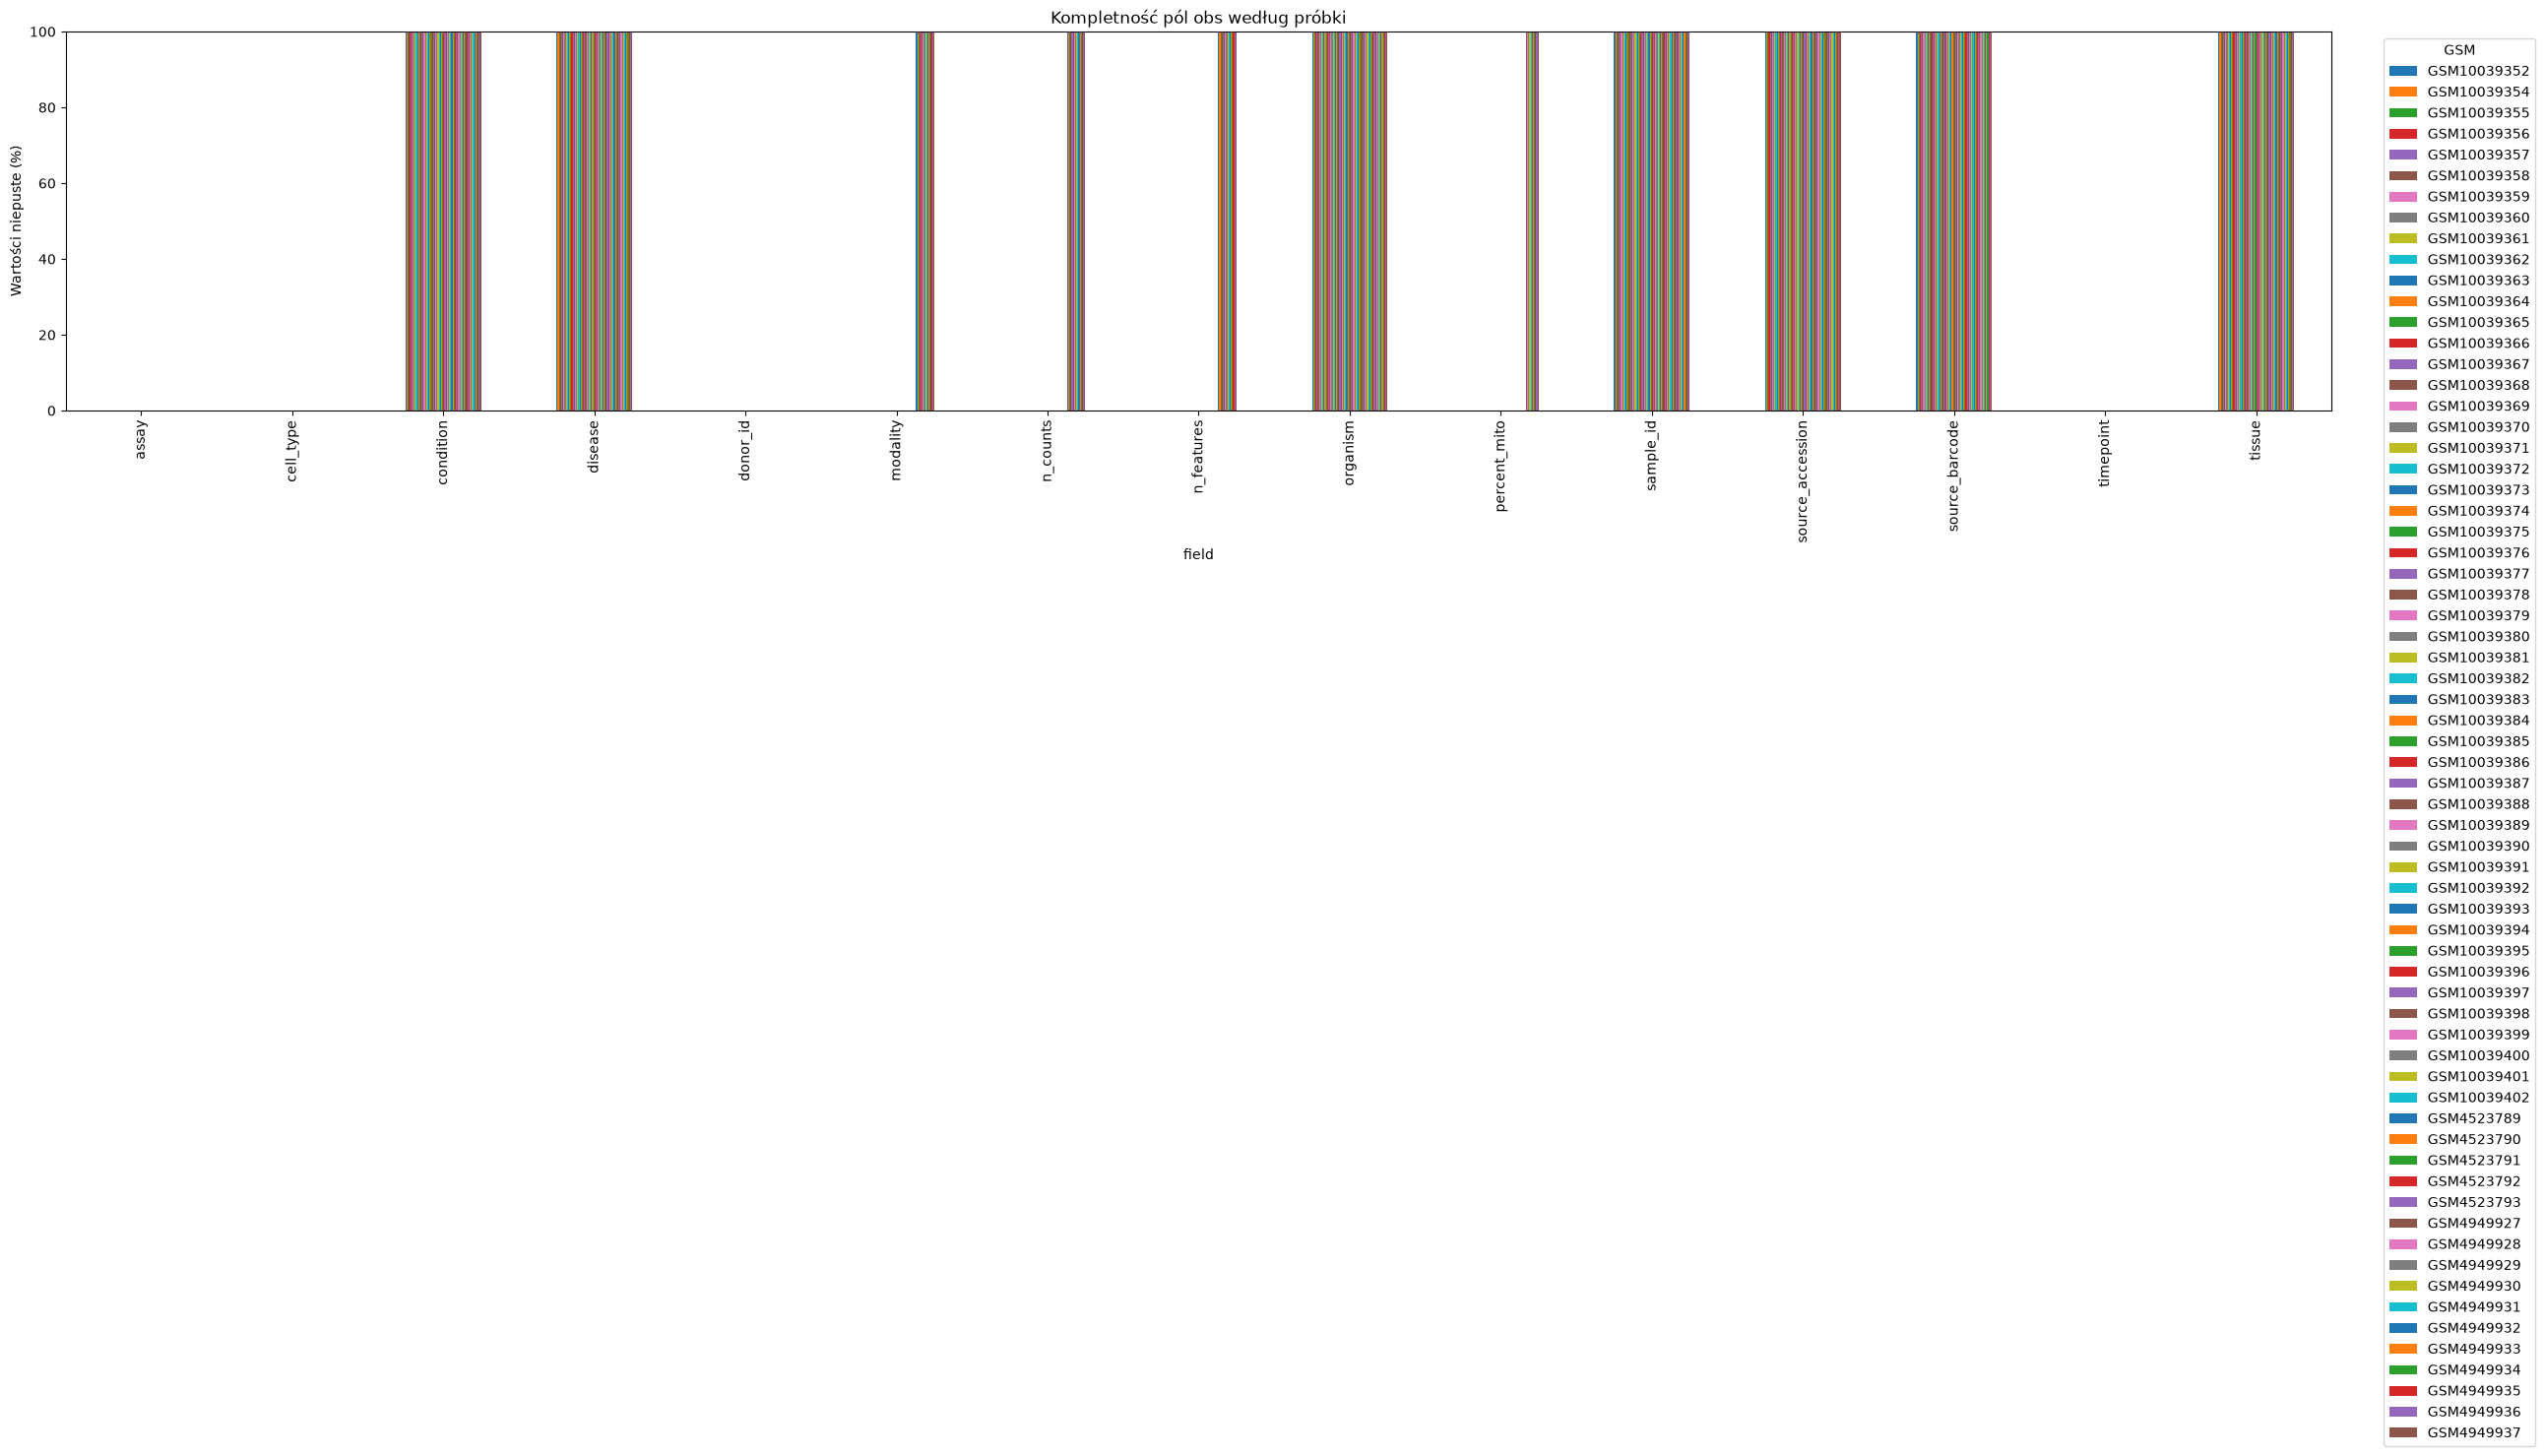

In [5]:
object_rows = []
obs_coverage = []
var_coverage = []
for (gse, gsm), adata in objects.items():
    x = adata.X
    x_storage = 'sparse' if sparse.issparse(x) else 'dense'
    object_rows.append({
        'GSE': gse, 'GSM/file': gsm, 'cells': adata.n_obs, 'features': adata.n_vars,
        'X storage': x_storage, 'X format': getattr(x, 'format', 'dense'),
        'X dtype': str(x.dtype), 'counts layer': 'counts' in adata.layers,
        'matrix_semantics': adata.uns.get('matrix_semantics', 'missing'),
        'obs index unique': adata.obs_names.is_unique, 'var index unique': adata.var_names.is_unique,
    })
    for axis, frame, target in [('obs', adata.obs, obs_coverage), ('var', adata.var, var_coverage)]:
        for col in frame.columns:
            non_null = int(frame[col].notna().sum())
            target.append({'GSE': gse, 'GSM/file': gsm, 'axis': axis, 'field': col,
                           'non_null': non_null, 'missing': int(len(frame) - non_null),
                           'non_null_pct': 100 * non_null / len(frame) if len(frame) else np.nan})

display(pd.DataFrame(object_rows))
obs_coverage_df = pd.DataFrame(obs_coverage)
var_coverage_df = pd.DataFrame(var_coverage)
print('Kompletność pól obs:')
display(obs_coverage_df)
print('Kompletność pól var:')
display(var_coverage_df)

if not obs_coverage_df.empty:
    pivot = obs_coverage_df.pivot(index='field', columns='GSM/file', values='non_null_pct').fillna(0)
    ax = pivot.plot(kind='bar', figsize=(max(10, len(pivot.columns) * 0.45), 5), ylim=(0, 100))
    ax.set_ylabel('Wartości niepuste (%)')
    ax.set_title('Kompletność pól obs według próbki')
    ax.legend(title='GSM', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()


## Podgląd zawartości obiektów

Dla każdego obiektu wyświetlane są pierwsze wiersze `obs` i `var` oraz mały wycinek `X`. Wycinek przedstawia zapisane wartości bez normalizacji ani innej transformacji.



### GSE150115 / GSM4523789 — 4000 komórek × 25223 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM4523789:ACATCCCGTATC,GSM4523789,ACATCCCGTATC,<NA>,Homo sapiens,Colonic lamina propria,<NA>,active ulcerative colitis,active ulcerative colitis,<NA>,scRNA-seq,<NA>,GSE150115,26942,5677,NaN
GSM4523789:CGTCCCAATTCA,GSM4523789,CGTCCCAATTCA,<NA>,Homo sapiens,Colonic lamina propria,<NA>,active ulcerative colitis,active ulcerative colitis,<NA>,scRNA-seq,<NA>,GSE150115,25081,5950,NaN
GSM4523789:CCCATGGAACGA,GSM4523789,CCCATGGAACGA,<NA>,Homo sapiens,Colonic lamina propria,<NA>,active ulcerative colitis,active ulcerative colitis,<NA>,scRNA-seq,<NA>,GSE150115,17591,4293,NaN
GSM4523789:GCCGAACCTCTC,GSM4523789,GCCGAACCTCTC,<NA>,Homo sapiens,Colonic lamina propria,<NA>,active ulcerative colitis,active ulcerative colitis,<NA>,scRNA-seq,<NA>,GSE150115,18645,5030,NaN
GSM4523789:GCCAAGAGGTCA,GSM4523789,GCCAAGAGGTCA,<NA>,Homo sapiens,Colonic lamina propria,<NA>,active ulcerative colitis,active ulcerative colitis,<NA>,scRNA-seq,<NA>,GSE150115,12392,3450,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
A1BG,A1BG,<NA>,hg19
A1BG-AS1,A1BG-AS1,<NA>,hg19
A1CF,A1CF,<NA>,hg19
A2M,A2M,<NA>,hg19
A2M-AS1,A2M-AS1,<NA>,hg19


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE150115',
 'source_format': {'file': 'GSE150115_RAW.tar',
  'format': 'dense gene-by-cell DGE TSV in TAR',
  'member': 'GSM4523789_reads.Snap1LAM_B_S2_R1_001.fastq_bq10_star_corrected.umi.dge.txt.gz',
  'source_sha256': '4ce584efcffdf8851fb73674464fde4e843e8b35a3d40e21b2776029bd4b3f4d'},
 'matrix_semantics': 'raw counts',
 'feature_id_namespace': 'source-supplied gene symbols',
 'harmonization_notes': 'Loaded unfiltered UMI-collapsed DGE values without normalization; raw-count semantics and hg19 were confirmed from GEO source documentation.'}

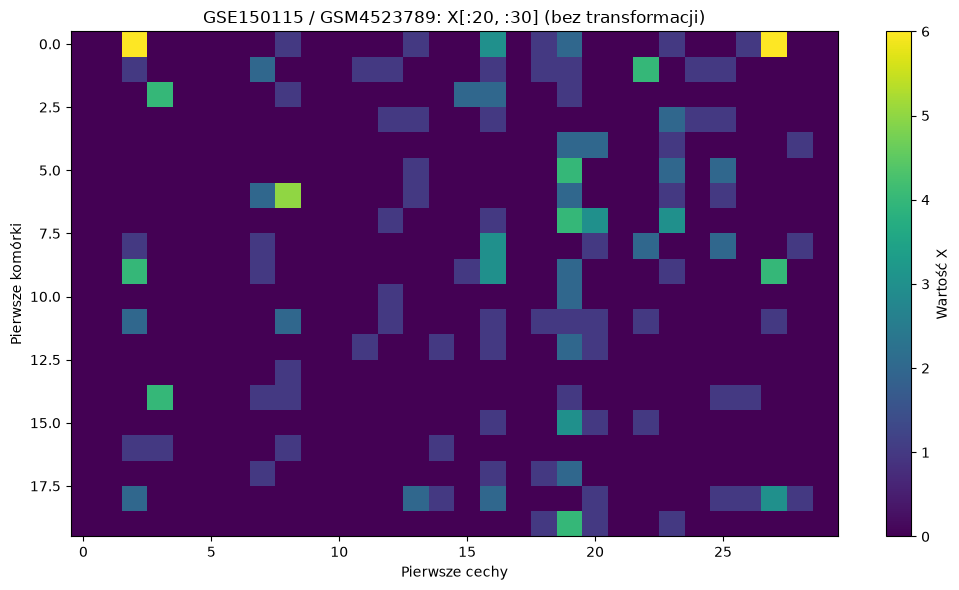


### GSE150115 / GSM4523790 — 4000 komórek × 24231 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM4523790:CGAAGCGACTAA,GSM4523790,CGAAGCGACTAA,<NA>,Homo sapiens,Colonic lamina propria,<NA>,active ulcerative colitis,active ulcerative colitis,<NA>,scRNA-seq,<NA>,GSE150115,43840,7368,NaN
GSM4523790:ACGTCTTAAGGC,GSM4523790,ACGTCTTAAGGC,<NA>,Homo sapiens,Colonic lamina propria,<NA>,active ulcerative colitis,active ulcerative colitis,<NA>,scRNA-seq,<NA>,GSE150115,34420,7119,NaN
GSM4523790:TACTAGGTTTTC,GSM4523790,TACTAGGTTTTC,<NA>,Homo sapiens,Colonic lamina propria,<NA>,active ulcerative colitis,active ulcerative colitis,<NA>,scRNA-seq,<NA>,GSE150115,38302,7496,NaN
GSM4523790:GCGTAACGAGGC,GSM4523790,GCGTAACGAGGC,<NA>,Homo sapiens,Colonic lamina propria,<NA>,active ulcerative colitis,active ulcerative colitis,<NA>,scRNA-seq,<NA>,GSE150115,20594,5268,NaN
GSM4523790:GGAGAAATAGGA,GSM4523790,GGAGAAATAGGA,<NA>,Homo sapiens,Colonic lamina propria,<NA>,active ulcerative colitis,active ulcerative colitis,<NA>,scRNA-seq,<NA>,GSE150115,23476,5399,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
A1BG,A1BG,<NA>,hg19
A1BG-AS1,A1BG-AS1,<NA>,hg19
A1CF,A1CF,<NA>,hg19
A2M,A2M,<NA>,hg19
A2M-AS1,A2M-AS1,<NA>,hg19


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE150115',
 'source_format': {'file': 'GSE150115_RAW.tar',
  'format': 'dense gene-by-cell DGE TSV in TAR',
  'member': 'GSM4523790_reads.Snap2LAM_B_S2_R1_001.fastq_bq10_star_corrected.umi.dge_1_.txt.gz',
  'source_sha256': '4ce584efcffdf8851fb73674464fde4e843e8b35a3d40e21b2776029bd4b3f4d'},
 'matrix_semantics': 'raw counts',
 'feature_id_namespace': 'source-supplied gene symbols',
 'harmonization_notes': 'Loaded unfiltered UMI-collapsed DGE values without normalization; raw-count semantics and hg19 were confirmed from GEO source documentation.'}

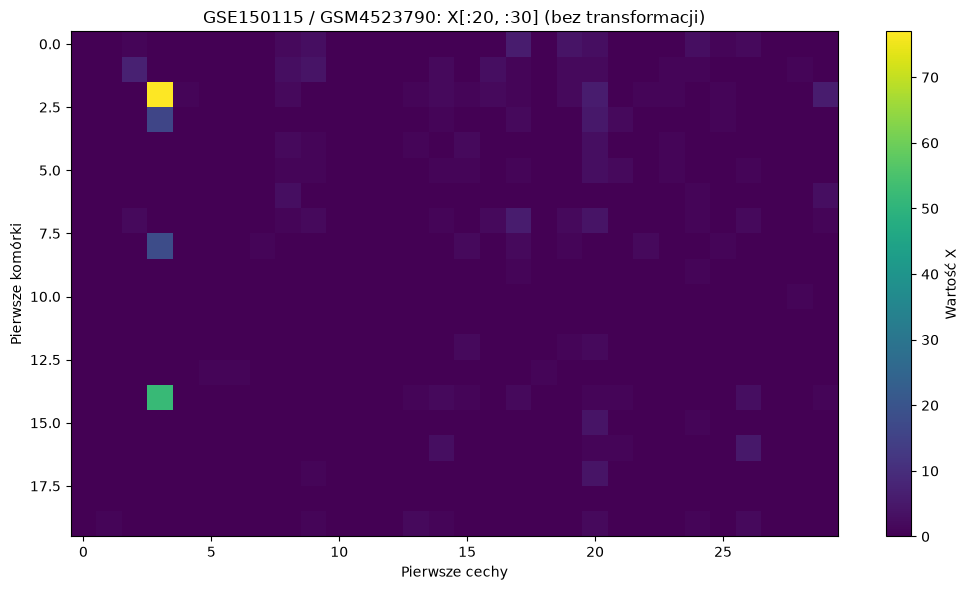


### GSE150115 / GSM4523791 — 4000 komórek × 26983 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM4523791:GCACGCGCCTAT,GSM4523791,GCACGCGCCTAT,<NA>,Homo sapiens,Colonic lamina propria,<NA>,active ulcerative colitis,active ulcerative colitis,<NA>,scRNA-seq,<NA>,GSE150115,14516,2881,NaN
GSM4523791:AAAAGGTGTTCT,GSM4523791,AAAAGGTGTTCT,<NA>,Homo sapiens,Colonic lamina propria,<NA>,active ulcerative colitis,active ulcerative colitis,<NA>,scRNA-seq,<NA>,GSE150115,25910,5784,NaN
GSM4523791:CATCTACGGTGA,GSM4523791,CATCTACGGTGA,<NA>,Homo sapiens,Colonic lamina propria,<NA>,active ulcerative colitis,active ulcerative colitis,<NA>,scRNA-seq,<NA>,GSE150115,21404,5339,NaN
GSM4523791:GACAATTCCATG,GSM4523791,GACAATTCCATG,<NA>,Homo sapiens,Colonic lamina propria,<NA>,active ulcerative colitis,active ulcerative colitis,<NA>,scRNA-seq,<NA>,GSE150115,20186,5580,NaN
GSM4523791:AGGTCCCAAGTG,GSM4523791,AGGTCCCAAGTG,<NA>,Homo sapiens,Colonic lamina propria,<NA>,active ulcerative colitis,active ulcerative colitis,<NA>,scRNA-seq,<NA>,GSE150115,21869,5547,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
A1BG,A1BG,<NA>,hg19
A1BG-AS1,A1BG-AS1,<NA>,hg19
A1CF,A1CF,<NA>,hg19
A2M,A2M,<NA>,hg19
A2M-AS1,A2M-AS1,<NA>,hg19


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE150115',
 'source_format': {'file': 'GSE150115_RAW.tar',
  'format': 'dense gene-by-cell DGE TSV in TAR',
  'member': 'GSM4523791_reads.Snap3LAM_B_S4_R1_001.fastq_bq10_star_corrected.umi.dge.txt.gz',
  'source_sha256': '4ce584efcffdf8851fb73674464fde4e843e8b35a3d40e21b2776029bd4b3f4d'},
 'matrix_semantics': 'raw counts',
 'feature_id_namespace': 'source-supplied gene symbols',
 'harmonization_notes': 'Loaded unfiltered UMI-collapsed DGE values without normalization; raw-count semantics and hg19 were confirmed from GEO source documentation.'}

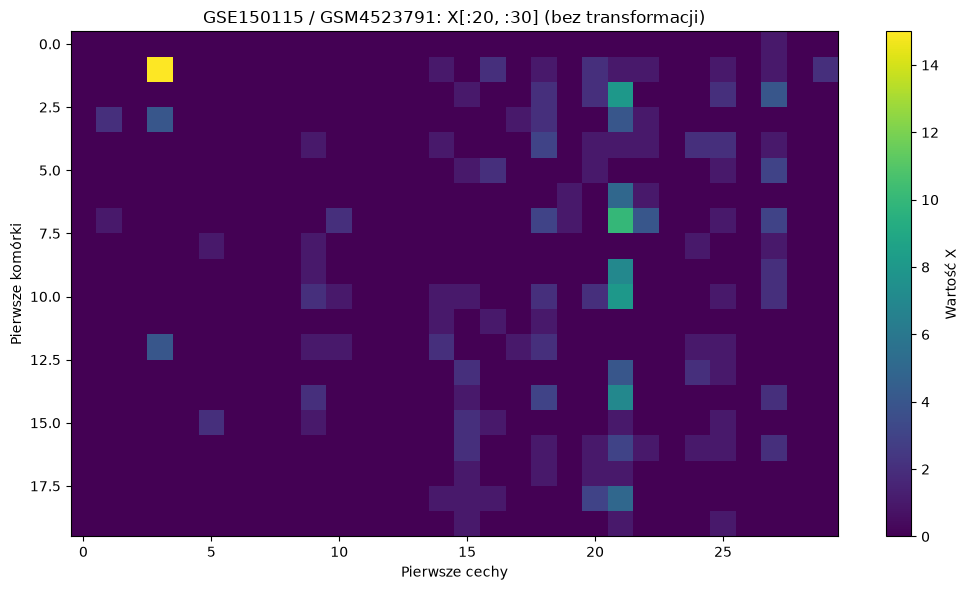


### GSE150115 / GSM4523792 — 10000 komórek × 31840 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM4523792:GCGCGCAGTGTG,GSM4523792,GCGCGCAGTGTG,<NA>,Homo sapiens,Colonic lamina propria,<NA>,active ulcerative colitis,active ulcerative colitis,<NA>,scRNA-seq,<NA>,GSE150115,514,463,NaN
GSM4523792:TTTGTCGGTCAT,GSM4523792,TTTGTCGGTCAT,<NA>,Homo sapiens,Colonic lamina propria,<NA>,active ulcerative colitis,active ulcerative colitis,<NA>,scRNA-seq,<NA>,GSE150115,514,429,NaN
GSM4523792:ATGTGGCGTATT,GSM4523792,ATGTGGCGTATT,<NA>,Homo sapiens,Colonic lamina propria,<NA>,active ulcerative colitis,active ulcerative colitis,<NA>,scRNA-seq,<NA>,GSE150115,257,231,NaN
GSM4523792:TAGGCATAGCGG,GSM4523792,TAGGCATAGCGG,<NA>,Homo sapiens,Colonic lamina propria,<NA>,active ulcerative colitis,active ulcerative colitis,<NA>,scRNA-seq,<NA>,GSE150115,400,365,NaN
GSM4523792:ACGTCAACTGTG,GSM4523792,ACGTCAACTGTG,<NA>,Homo sapiens,Colonic lamina propria,<NA>,active ulcerative colitis,active ulcerative colitis,<NA>,scRNA-seq,<NA>,GSE150115,247,234,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
A1BG,A1BG,<NA>,hg19
A1BG-AS1,A1BG-AS1,<NA>,hg19
A1CF,A1CF,<NA>,hg19
A2M,A2M,<NA>,hg19
A2M-AS1,A2M-AS1,<NA>,hg19


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE150115',
 'source_format': {'file': 'GSE150115_RAW.tar',
  'format': 'dense gene-by-cell DGE TSV in TAR',
  'member': 'GSM4523792_reads.Snap4_LAM_B_S2_R1_001.fastq_bq10_star_corrected.umi.dge.txt.gz',
  'source_sha256': '4ce584efcffdf8851fb73674464fde4e843e8b35a3d40e21b2776029bd4b3f4d'},
 'matrix_semantics': 'raw counts',
 'feature_id_namespace': 'source-supplied gene symbols',
 'harmonization_notes': 'Loaded unfiltered UMI-collapsed DGE values without normalization; raw-count semantics and hg19 were confirmed from GEO source documentation.'}

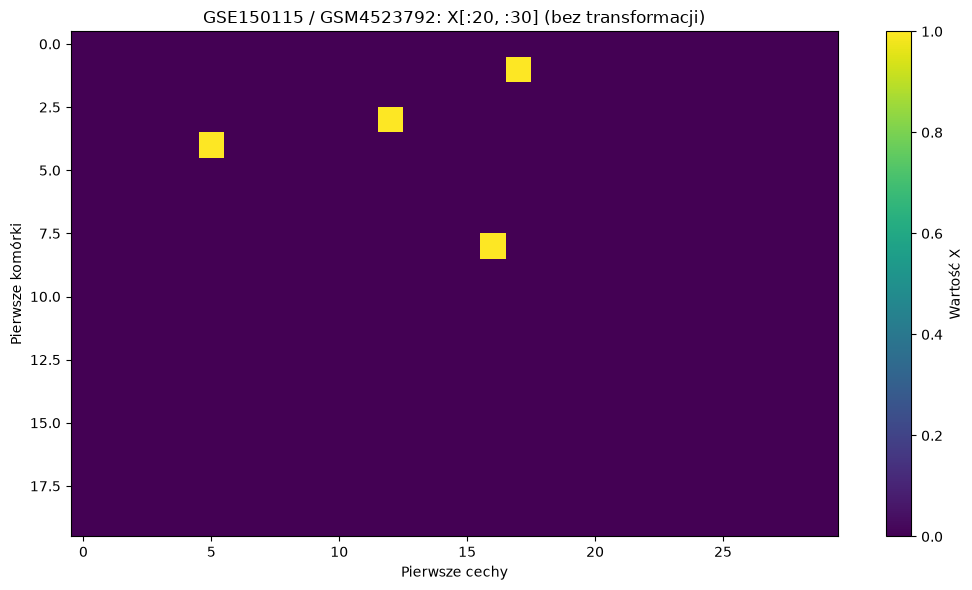


### GSE150115 / GSM4523793 — 10000 komórek × 32263 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM4523793:GCCAGAGGGTGA,GSM4523793,GCCAGAGGGTGA,<NA>,Homo sapiens,Colonic lamina propria,<NA>,active ulcerative colitis,active ulcerative colitis,<NA>,scRNA-seq,<NA>,GSE150115,598,527,NaN
GSM4523793:GCACCAAGATTA,GSM4523793,GCACCAAGATTA,<NA>,Homo sapiens,Colonic lamina propria,<NA>,active ulcerative colitis,active ulcerative colitis,<NA>,scRNA-seq,<NA>,GSE150115,3082,838,NaN
GSM4523793:CTCATCCCGATT,GSM4523793,CTCATCCCGATT,<NA>,Homo sapiens,Colonic lamina propria,<NA>,active ulcerative colitis,active ulcerative colitis,<NA>,scRNA-seq,<NA>,GSE150115,344,285,NaN
GSM4523793:GGTCCCGCAACC,GSM4523793,GGTCCCGCAACC,<NA>,Homo sapiens,Colonic lamina propria,<NA>,active ulcerative colitis,active ulcerative colitis,<NA>,scRNA-seq,<NA>,GSE150115,339,290,NaN
GSM4523793:GAACATTCTAGG,GSM4523793,GAACATTCTAGG,<NA>,Homo sapiens,Colonic lamina propria,<NA>,active ulcerative colitis,active ulcerative colitis,<NA>,scRNA-seq,<NA>,GSE150115,419,294,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
A1BG,A1BG,<NA>,hg19
A1BG-AS1,A1BG-AS1,<NA>,hg19
A1CF,A1CF,<NA>,hg19
A2M,A2M,<NA>,hg19
A2M-AS1,A2M-AS1,<NA>,hg19


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE150115',
 'source_format': {'file': 'GSE150115_RAW.tar',
  'format': 'dense gene-by-cell DGE TSV in TAR',
  'member': 'GSM4523793_reads.Snap5_LAM_B_S3_R1_001.fastq_bq10_star_corrected.umi.dge.txt.gz',
  'source_sha256': '4ce584efcffdf8851fb73674464fde4e843e8b35a3d40e21b2776029bd4b3f4d'},
 'matrix_semantics': 'raw counts',
 'feature_id_namespace': 'source-supplied gene symbols',
 'harmonization_notes': 'Loaded unfiltered UMI-collapsed DGE values without normalization; raw-count semantics and hg19 were confirmed from GEO source documentation.'}

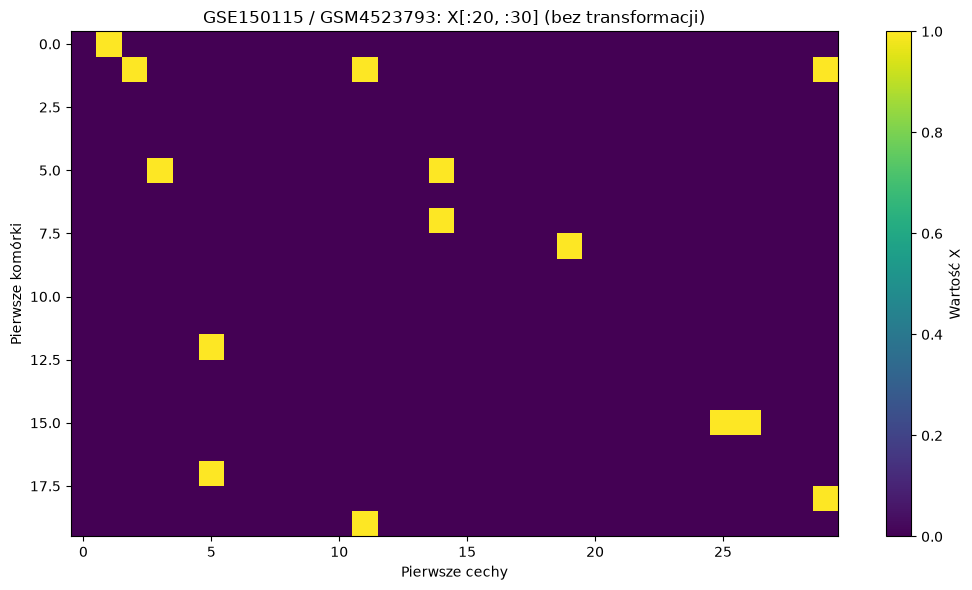


### GSE162335 / GSM4949927 — 1519 komórek × 25332 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM4949927:AG.AAACGAACACTACCCT,GSM4949927,AG.AAACGAACACTACCCT,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,11195,2390,7.441
GSM4949927:AG.AAAGAACCACTGGCGT,GSM4949927,AG.AAAGAACCACTGGCGT,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,9361,2854,7.286
GSM4949927:AG.AAAGAACGTTCTTCAT,GSM4949927,AG.AAAGAACGTTCTTCAT,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,3111,1275,7.682
GSM4949927:AG.AAAGGATCATAATCCG,GSM4949927,AG.AAAGGATCATAATCCG,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,7828,1778,9.964
GSM4949927:AG.AAAGGGCTCTCTCAAT,GSM4949927,AG.AAAGGGCTCTCTCAAT,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,11506,2563,7.344


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
7SK.1,7SK.1,<NA>,GRCh38
7SK.2,7SK.2,<NA>,GRCh38
A1BG,A1BG,<NA>,GRCh38
A1BG-AS1,A1BG-AS1,<NA>,GRCh38
A2M,A2M,<NA>,GRCh38


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE162335',
 'source_format': {'file': 'GSE162335_RAW.tar',
  'format': 'dense gene-by-cell DGE TSV in TAR',
  'member': 'GSM4949927_SingleCellCounts_UCI_1.txt.gz',
  'source_sha256': 'fcc0b11163da5b7ca68cf90e242b300c6530eb077ef0ba27e7208d346be0dc49'},
 'matrix_semantics': 'normalized',
 'feature_id_namespace': 'source-supplied symbol-like gene labels',
 'harmonization_notes': 'Loaded source normalized values without transformation; GEO documents Seurat LogNormalize (scale factor 10000). QC fields were joined by exact sample label, barcode set, and order. Source cell annotations were not copied; cell_type remains null.'}

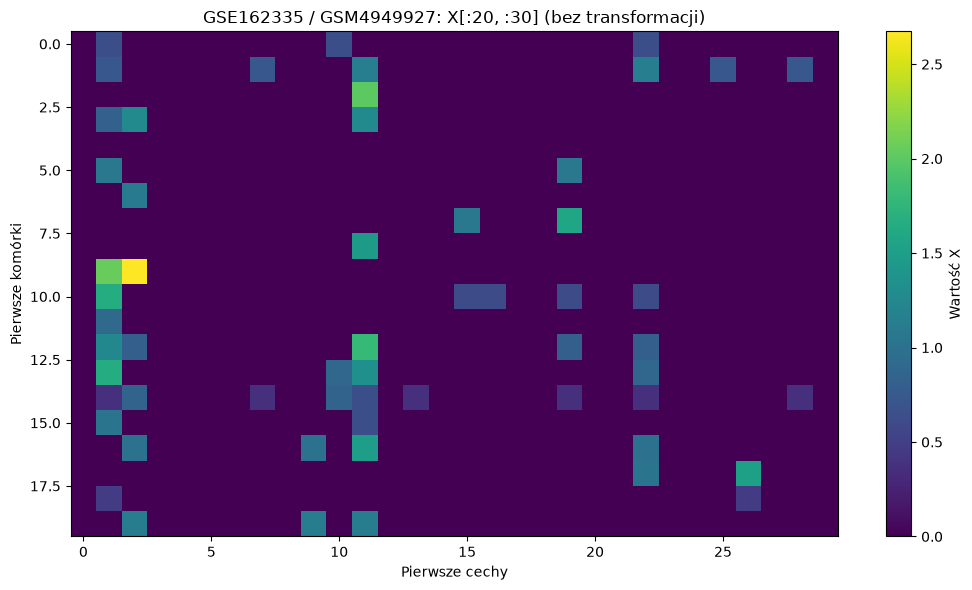


### GSE162335 / GSM4949928 — 1591 komórek × 25332 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM4949928:am.AAACCCATCAGACCCG,GSM4949928,am.AAACCCATCAGACCCG,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,3168,1162,4.040
GSM4949928:am.AAACGAACACAGTATC,GSM4949928,am.AAACGAACACAGTATC,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,6080,2147,3.586
GSM4949928:am.AAACGAACACGGCTAC,GSM4949928,am.AAACGAACACGGCTAC,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,2703,985,7.584
GSM4949928:am.AAACGCTTCAGCAATC,GSM4949928,am.AAACGCTTCAGCAATC,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,4585,1295,6.936
GSM4949928:am.AAAGGATAGTGAGGTC,GSM4949928,am.AAAGGATAGTGAGGTC,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,4901,1456,6.672


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
7SK.1,7SK.1,<NA>,GRCh38
7SK.2,7SK.2,<NA>,GRCh38
A1BG,A1BG,<NA>,GRCh38
A1BG-AS1,A1BG-AS1,<NA>,GRCh38
A2M,A2M,<NA>,GRCh38


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE162335',
 'source_format': {'file': 'GSE162335_RAW.tar',
  'format': 'dense gene-by-cell DGE TSV in TAR',
  'member': 'GSM4949928_SingleCellCounts_UCI_2.txt.gz',
  'source_sha256': 'fcc0b11163da5b7ca68cf90e242b300c6530eb077ef0ba27e7208d346be0dc49'},
 'matrix_semantics': 'normalized',
 'feature_id_namespace': 'source-supplied symbol-like gene labels',
 'harmonization_notes': 'Loaded source normalized values without transformation; GEO documents Seurat LogNormalize (scale factor 10000). QC fields were joined by exact sample label, barcode set, and order. Source cell annotations were not copied; cell_type remains null.'}

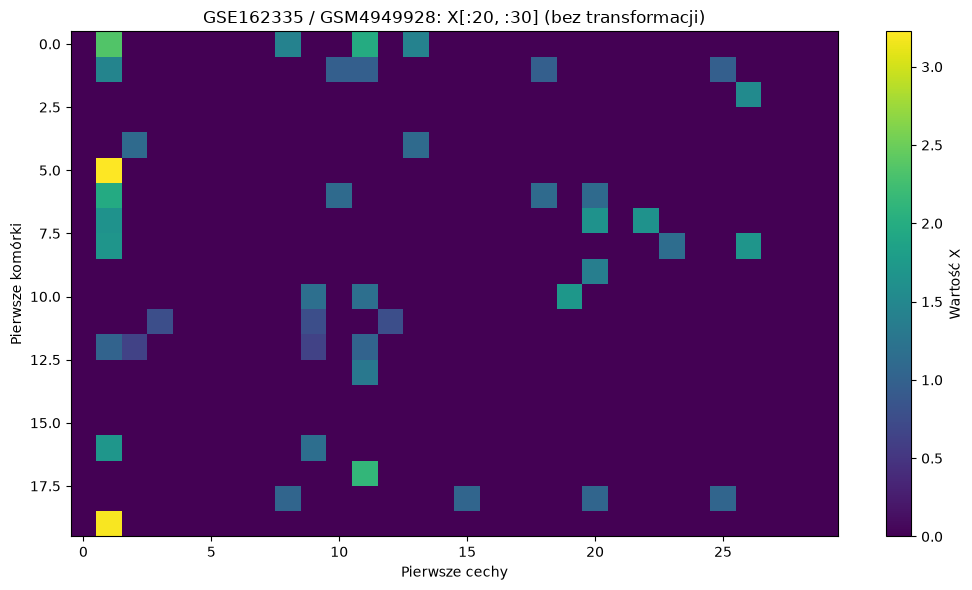


### GSE162335 / GSM4949929 — 1570 komórek × 25332 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM4949929:AM.AAACCCAGTAGCTTGT,GSM4949929,AM.AAACCCAGTAGCTTGT,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,17143,3888,9.059
GSM4949929:AM.AAACGAACAAGCTGTT,GSM4949929,AM.AAACGAACAAGCTGTT,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,5147,1752,7.869
GSM4949929:AM.AAACGAACAGGTCCGT,GSM4949929,AM.AAACGAACAGGTCCGT,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,10762,3145,4.507
GSM4949929:AM.AAACGAAGTAACATAG,GSM4949929,AM.AAACGAAGTAACATAG,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,4276,1580,6.876
GSM4949929:AM.AAACGAAGTTATTCTC,GSM4949929,AM.AAACGAAGTTATTCTC,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,14147,2943,3.563


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
7SK.1,7SK.1,<NA>,GRCh38
7SK.2,7SK.2,<NA>,GRCh38
A1BG,A1BG,<NA>,GRCh38
A1BG-AS1,A1BG-AS1,<NA>,GRCh38
A2M,A2M,<NA>,GRCh38


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE162335',
 'source_format': {'file': 'GSE162335_RAW.tar',
  'format': 'dense gene-by-cell DGE TSV in TAR',
  'member': 'GSM4949929_SingleCellCounts_UCI_3.txt.gz',
  'source_sha256': 'fcc0b11163da5b7ca68cf90e242b300c6530eb077ef0ba27e7208d346be0dc49'},
 'matrix_semantics': 'normalized',
 'feature_id_namespace': 'source-supplied symbol-like gene labels',
 'harmonization_notes': 'Loaded source normalized values without transformation; GEO documents Seurat LogNormalize (scale factor 10000). QC fields were joined by exact sample label, barcode set, and order. Source cell annotations were not copied; cell_type remains null.'}

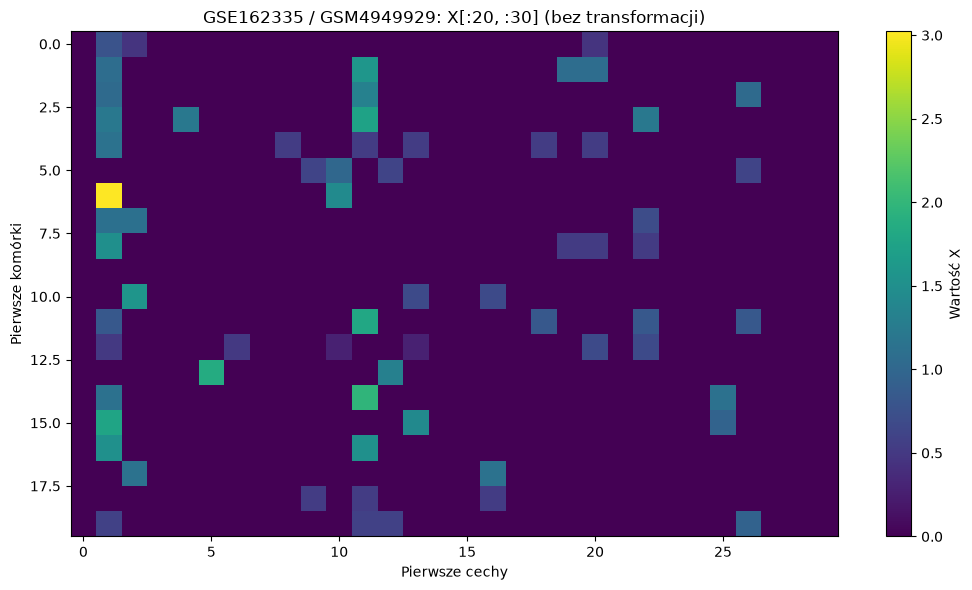


### GSE162335 / GSM4949930 — 1140 komórek × 25332 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM4949930:kk.AAACCCATCATTCATC,GSM4949930,kk.AAACCCATCATTCATC,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,14362,3108,6.448
GSM4949930:kk.AAACGCTAGTCTAGCT,GSM4949930,kk.AAACGCTAGTCTAGCT,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,4691,1550,8.314
GSM4949930:kk.AAAGAACTCGACCACG,GSM4949930,kk.AAAGAACTCGACCACG,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,3928,1110,6.212
GSM4949930:kk.AAAGGGCCAAATGGCG,GSM4949930,kk.AAAGGGCCAAATGGCG,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,7497,2317,8.030
GSM4949930:kk.AAAGGGCCATACAGAA,GSM4949930,kk.AAAGGGCCATACAGAA,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,5605,1888,5.299


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
7SK.1,7SK.1,<NA>,GRCh38
7SK.2,7SK.2,<NA>,GRCh38
A1BG,A1BG,<NA>,GRCh38
A1BG-AS1,A1BG-AS1,<NA>,GRCh38
A2M,A2M,<NA>,GRCh38


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE162335',
 'source_format': {'file': 'GSE162335_RAW.tar',
  'format': 'dense gene-by-cell DGE TSV in TAR',
  'member': 'GSM4949930_SingleCellCounts_UCI_4.txt.gz',
  'source_sha256': 'fcc0b11163da5b7ca68cf90e242b300c6530eb077ef0ba27e7208d346be0dc49'},
 'matrix_semantics': 'normalized',
 'feature_id_namespace': 'source-supplied symbol-like gene labels',
 'harmonization_notes': 'Loaded source normalized values without transformation; GEO documents Seurat LogNormalize (scale factor 10000). QC fields were joined by exact sample label, barcode set, and order. Source cell annotations were not copied; cell_type remains null.'}

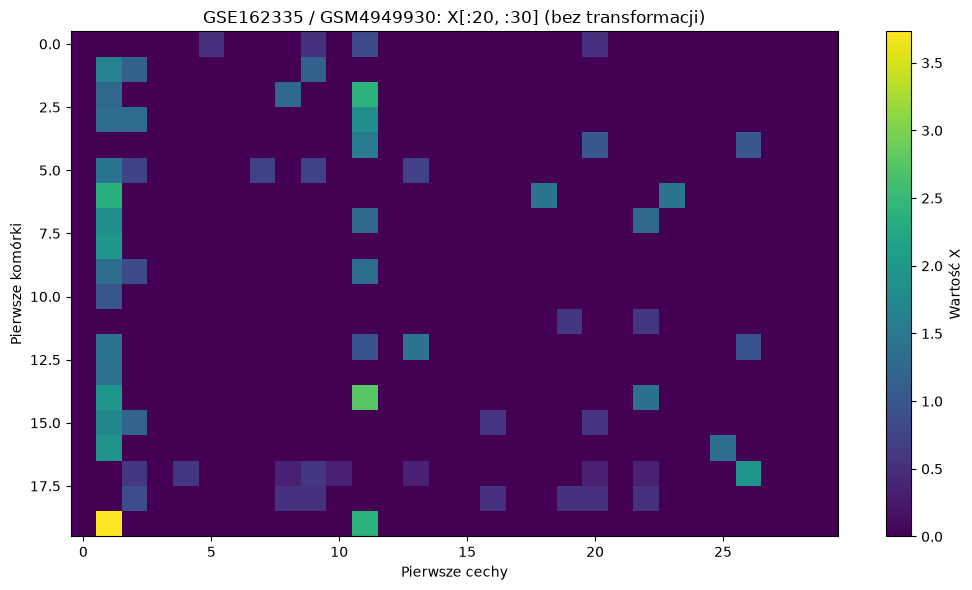


### GSE162335 / GSM4949931 — 1495 komórek × 25332 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM4949931:lb.AAACCCAAGGAGTCTG,GSM4949931,lb.AAACCCAAGGAGTCTG,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,2946,1268,5.771
GSM4949931:lb.AAACCCATCTGAGAAA,GSM4949931,lb.AAACCCATCTGAGAAA,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,9327,2563,6.079
GSM4949931:lb.AAACGAAGTTAAGTCC,GSM4949931,lb.AAACGAAGTTAAGTCC,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,4825,1628,6.301
GSM4949931:lb.AAACGCTCACCGCTAG,GSM4949931,lb.AAACGCTCACCGCTAG,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,4437,1350,6.446
GSM4949931:lb.AAACGCTGTCATTGCA,GSM4949931,lb.AAACGCTGTCATTGCA,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,3660,1263,9.262


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
7SK.1,7SK.1,<NA>,GRCh38
7SK.2,7SK.2,<NA>,GRCh38
A1BG,A1BG,<NA>,GRCh38
A1BG-AS1,A1BG-AS1,<NA>,GRCh38
A2M,A2M,<NA>,GRCh38


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE162335',
 'source_format': {'file': 'GSE162335_RAW.tar',
  'format': 'dense gene-by-cell DGE TSV in TAR',
  'member': 'GSM4949931_SingleCellCounts_UCI_5.txt.gz',
  'source_sha256': 'fcc0b11163da5b7ca68cf90e242b300c6530eb077ef0ba27e7208d346be0dc49'},
 'matrix_semantics': 'normalized',
 'feature_id_namespace': 'source-supplied symbol-like gene labels',
 'harmonization_notes': 'Loaded source normalized values without transformation; GEO documents Seurat LogNormalize (scale factor 10000). QC fields were joined by exact sample label, barcode set, and order. Source cell annotations were not copied; cell_type remains null.'}

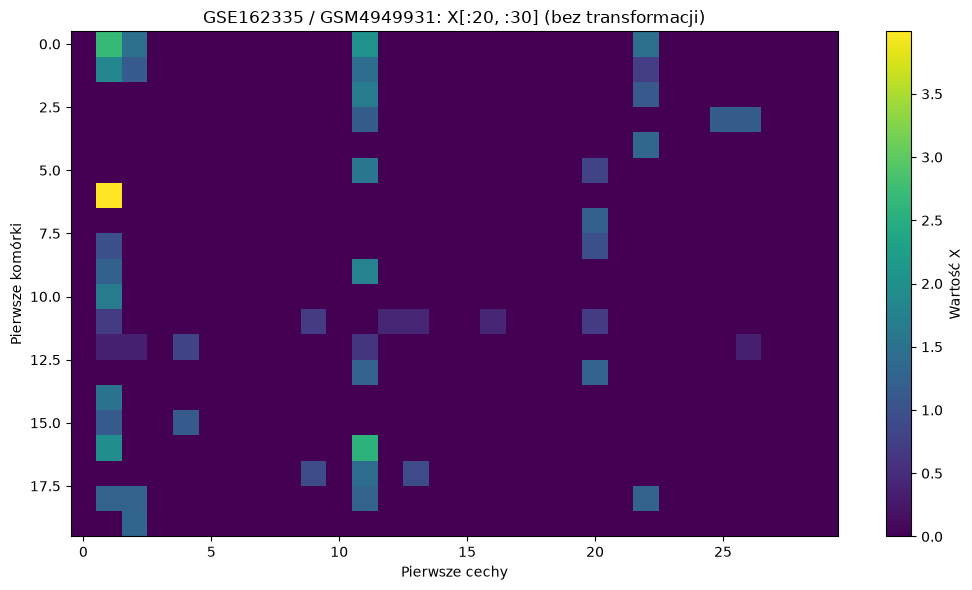


### GSE162335 / GSM4949932 — 2268 komórek × 25332 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM4949932:lm.AAACCCAAGCTGTTCA,GSM4949932,lm.AAACCCAAGCTGTTCA,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,5876,1888,8.764
GSM4949932:lm.AAACCCAAGTGTGTTC,GSM4949932,lm.AAACCCAAGTGTGTTC,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,6215,1621,8.302
GSM4949932:lm.AAACCCACACGAAAGC,GSM4949932,lm.AAACCCACACGAAAGC,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,15479,3406,8.360
GSM4949932:lm.AAACCCAGTGTTTGCA,GSM4949932,lm.AAACCCAGTGTTTGCA,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,6717,1644,9.186
GSM4949932:lm.AAACGAACACCGGCTA,GSM4949932,lm.AAACGAACACCGGCTA,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,3083,1412,9.698


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
7SK.1,7SK.1,<NA>,GRCh38
7SK.2,7SK.2,<NA>,GRCh38
A1BG,A1BG,<NA>,GRCh38
A1BG-AS1,A1BG-AS1,<NA>,GRCh38
A2M,A2M,<NA>,GRCh38


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE162335',
 'source_format': {'file': 'GSE162335_RAW.tar',
  'format': 'dense gene-by-cell DGE TSV in TAR',
  'member': 'GSM4949932_SingleCellCounts_UCI_6.txt.gz',
  'source_sha256': 'fcc0b11163da5b7ca68cf90e242b300c6530eb077ef0ba27e7208d346be0dc49'},
 'matrix_semantics': 'normalized',
 'feature_id_namespace': 'source-supplied symbol-like gene labels',
 'harmonization_notes': 'Loaded source normalized values without transformation; GEO documents Seurat LogNormalize (scale factor 10000). QC fields were joined by exact sample label, barcode set, and order. Source cell annotations were not copied; cell_type remains null.'}

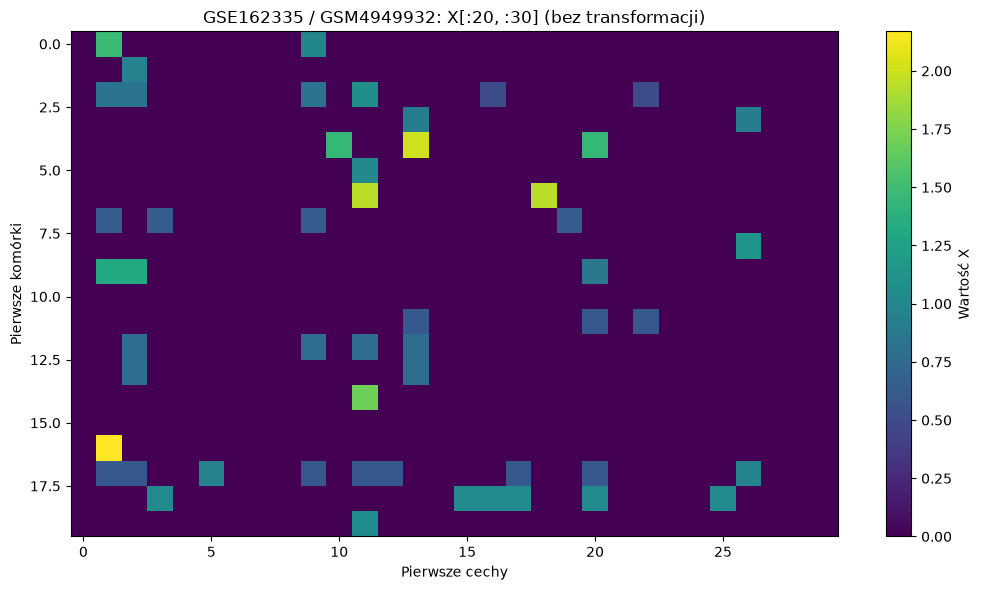


### GSE162335 / GSM4949933 — 2648 komórek × 25332 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM4949933:mc.AAACCCAAGACGACTG,GSM4949933,mc.AAACCCAAGACGACTG,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,8022,1878,9.998
GSM4949933:mc.AAACCCAAGATGCTAA,GSM4949933,mc.AAACCCAAGATGCTAA,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,3471,1323,8.701
GSM4949933:mc.AAACCCATCCTAGCCT,GSM4949933,mc.AAACCCATCCTAGCCT,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,11740,3729,6.635
GSM4949933:mc.AAACGAAAGCAGATAT,GSM4949933,mc.AAACGAAAGCAGATAT,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,1267,550,0.237
GSM4949933:mc.AAACGAAAGCTACAAA,GSM4949933,mc.AAACGAAAGCTACAAA,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,6273,1801,9.182


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
7SK.1,7SK.1,<NA>,GRCh38
7SK.2,7SK.2,<NA>,GRCh38
A1BG,A1BG,<NA>,GRCh38
A1BG-AS1,A1BG-AS1,<NA>,GRCh38
A2M,A2M,<NA>,GRCh38


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE162335',
 'source_format': {'file': 'GSE162335_RAW.tar',
  'format': 'dense gene-by-cell DGE TSV in TAR',
  'member': 'GSM4949933_SingleCellCounts_UCI_7.txt.gz',
  'source_sha256': 'fcc0b11163da5b7ca68cf90e242b300c6530eb077ef0ba27e7208d346be0dc49'},
 'matrix_semantics': 'normalized',
 'feature_id_namespace': 'source-supplied symbol-like gene labels',
 'harmonization_notes': 'Loaded source normalized values without transformation; GEO documents Seurat LogNormalize (scale factor 10000). QC fields were joined by exact sample label, barcode set, and order. Source cell annotations were not copied; cell_type remains null.'}

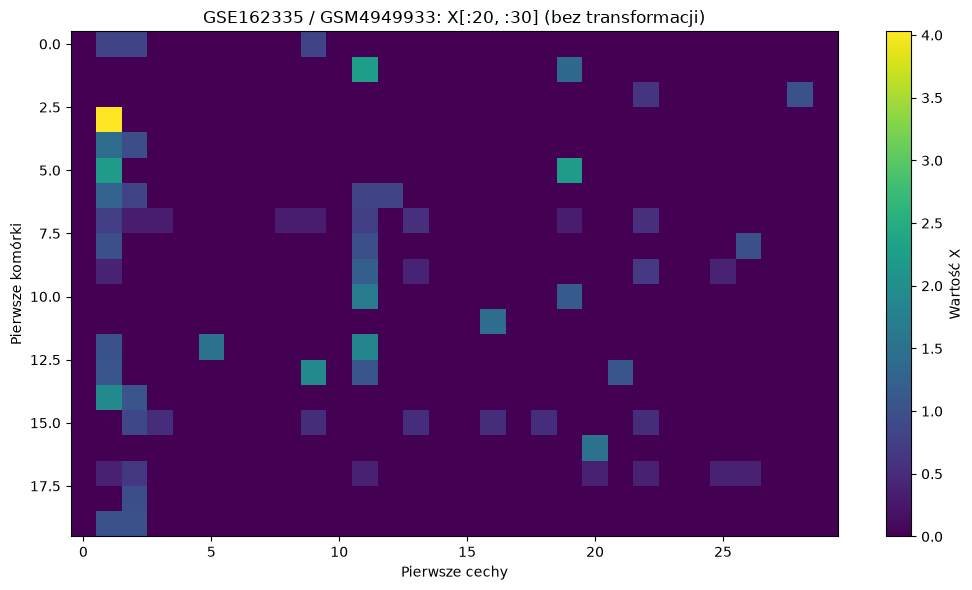


### GSE162335 / GSM4949934 — 1993 komórek × 25332 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM4949934:rk.AAACCCAAGATTAGAC,GSM4949934,rk.AAACCCAAGATTAGAC,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,5083,1215,6.591
GSM4949934:rk.AAACCCACAGTTTCGA,GSM4949934,rk.AAACCCACAGTTTCGA,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,7184,1853,8.839
GSM4949934:rk.AAACGAATCCTCACCA,GSM4949934,rk.AAACGAATCCTCACCA,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,1320,528,0.227
GSM4949934:rk.AAACGAATCGACCATA,GSM4949934,rk.AAACGAATCGACCATA,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,6695,1504,4.899
GSM4949934:rk.AAACGAATCTCTCAAT,GSM4949934,rk.AAACGAATCTCTCAAT,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,835,387,2.635


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
7SK.1,7SK.1,<NA>,GRCh38
7SK.2,7SK.2,<NA>,GRCh38
A1BG,A1BG,<NA>,GRCh38
A1BG-AS1,A1BG-AS1,<NA>,GRCh38
A2M,A2M,<NA>,GRCh38


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE162335',
 'source_format': {'file': 'GSE162335_RAW.tar',
  'format': 'dense gene-by-cell DGE TSV in TAR',
  'member': 'GSM4949934_SingleCellCounts_UCI_8.txt.gz',
  'source_sha256': 'fcc0b11163da5b7ca68cf90e242b300c6530eb077ef0ba27e7208d346be0dc49'},
 'matrix_semantics': 'normalized',
 'feature_id_namespace': 'source-supplied symbol-like gene labels',
 'harmonization_notes': 'Loaded source normalized values without transformation; GEO documents Seurat LogNormalize (scale factor 10000). QC fields were joined by exact sample label, barcode set, and order. Source cell annotations were not copied; cell_type remains null.'}

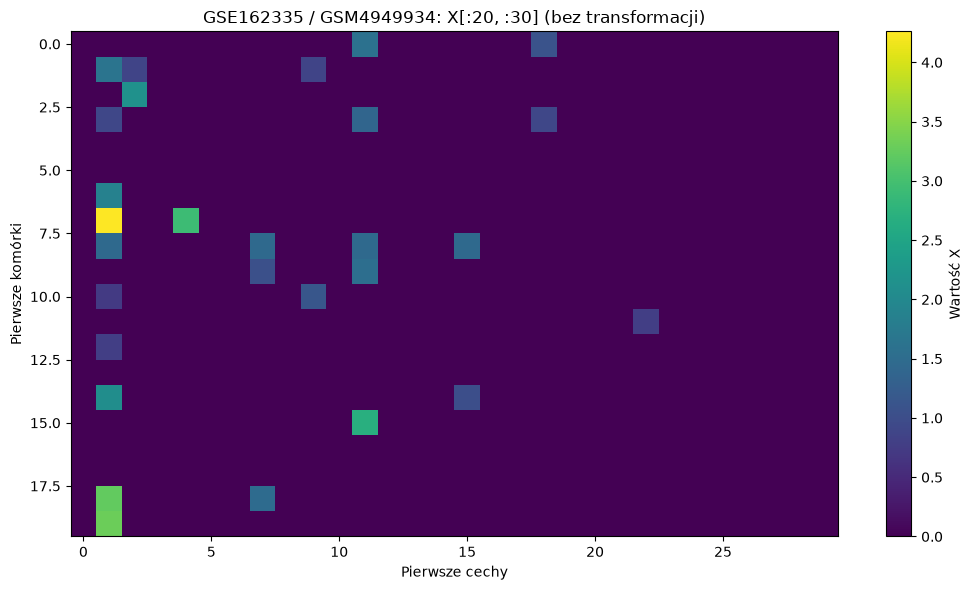


### GSE162335 / GSM4949935 — 1540 komórek × 25332 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM4949935:rm.AAACCCAGTACGGTTT,GSM4949935,rm.AAACCCAGTACGGTTT,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,3730,1592,7.534
GSM4949935:rm.AAACCCATCCGAACGC,GSM4949935,rm.AAACCCATCCGAACGC,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,3587,1274,3.875
GSM4949935:rm.AAACGAAAGGACTATA,GSM4949935,rm.AAACGAAAGGACTATA,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,13317,3636,4.475
GSM4949935:rm.AAAGAACAGAGATCGC,GSM4949935,rm.AAAGAACAGAGATCGC,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,5595,1460,6.988
GSM4949935:rm.AAAGGATAGGTAGTCG,GSM4949935,rm.AAAGGATAGGTAGTCG,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,3899,1657,2.411


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
7SK.1,7SK.1,<NA>,GRCh38
7SK.2,7SK.2,<NA>,GRCh38
A1BG,A1BG,<NA>,GRCh38
A1BG-AS1,A1BG-AS1,<NA>,GRCh38
A2M,A2M,<NA>,GRCh38


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE162335',
 'source_format': {'file': 'GSE162335_RAW.tar',
  'format': 'dense gene-by-cell DGE TSV in TAR',
  'member': 'GSM4949935_SingleCellCounts_UCI_9.txt.gz',
  'source_sha256': 'fcc0b11163da5b7ca68cf90e242b300c6530eb077ef0ba27e7208d346be0dc49'},
 'matrix_semantics': 'normalized',
 'feature_id_namespace': 'source-supplied symbol-like gene labels',
 'harmonization_notes': 'Loaded source normalized values without transformation; GEO documents Seurat LogNormalize (scale factor 10000). QC fields were joined by exact sample label, barcode set, and order. Source cell annotations were not copied; cell_type remains null.'}

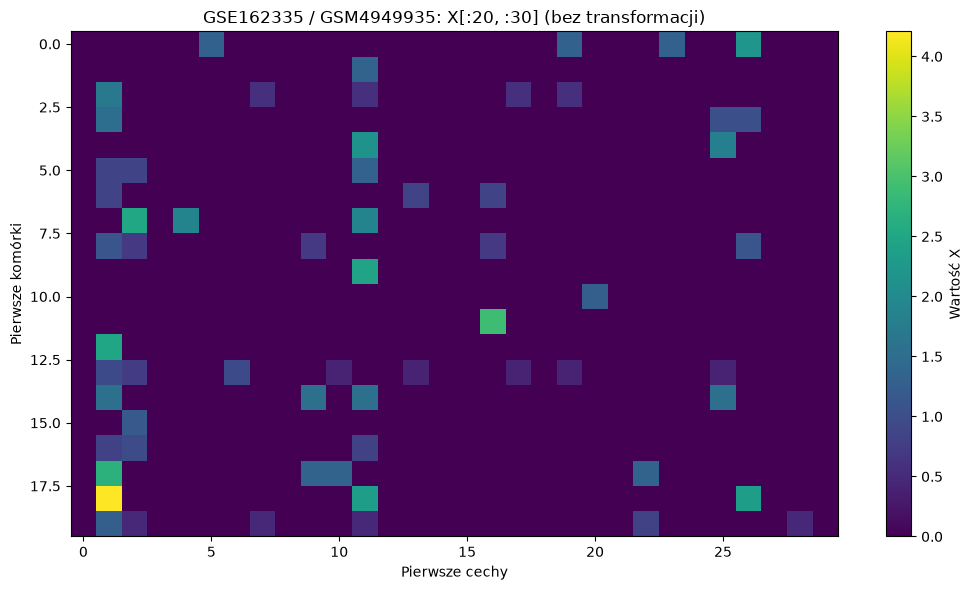


### GSE162335 / GSM4949936 — 1177 komórek × 25332 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM4949936:sb.AAACGAAAGCTTTCCC,GSM4949936,sb.AAACGAAAGCTTTCCC,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,7106,1913,9.471
GSM4949936:sb.AAACGCTAGGGATGTC,GSM4949936,sb.AAACGCTAGGGATGTC,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,3260,1620,4.448
GSM4949936:sb.AAAGAACCATCAGTGT,GSM4949936,sb.AAAGAACCATCAGTGT,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,845,536,4.852
GSM4949936:sb.AAAGGATTCGGCATAT,GSM4949936,sb.AAAGGATTCGGCATAT,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,10198,2591,9.933
GSM4949936:sb.AAAGGGCAGGGACACT,GSM4949936,sb.AAAGGGCAGGGACACT,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,8172,1925,9.092


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
7SK.1,7SK.1,<NA>,GRCh38
7SK.2,7SK.2,<NA>,GRCh38
A1BG,A1BG,<NA>,GRCh38
A1BG-AS1,A1BG-AS1,<NA>,GRCh38
A2M,A2M,<NA>,GRCh38


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE162335',
 'source_format': {'file': 'GSE162335_RAW.tar',
  'format': 'dense gene-by-cell DGE TSV in TAR',
  'member': 'GSM4949936_SingleCellCounts_UCI_10.txt.gz',
  'source_sha256': 'fcc0b11163da5b7ca68cf90e242b300c6530eb077ef0ba27e7208d346be0dc49'},
 'matrix_semantics': 'normalized',
 'feature_id_namespace': 'source-supplied symbol-like gene labels',
 'harmonization_notes': 'Loaded source normalized values without transformation; GEO documents Seurat LogNormalize (scale factor 10000). QC fields were joined by exact sample label, barcode set, and order. Source cell annotations were not copied; cell_type remains null.'}

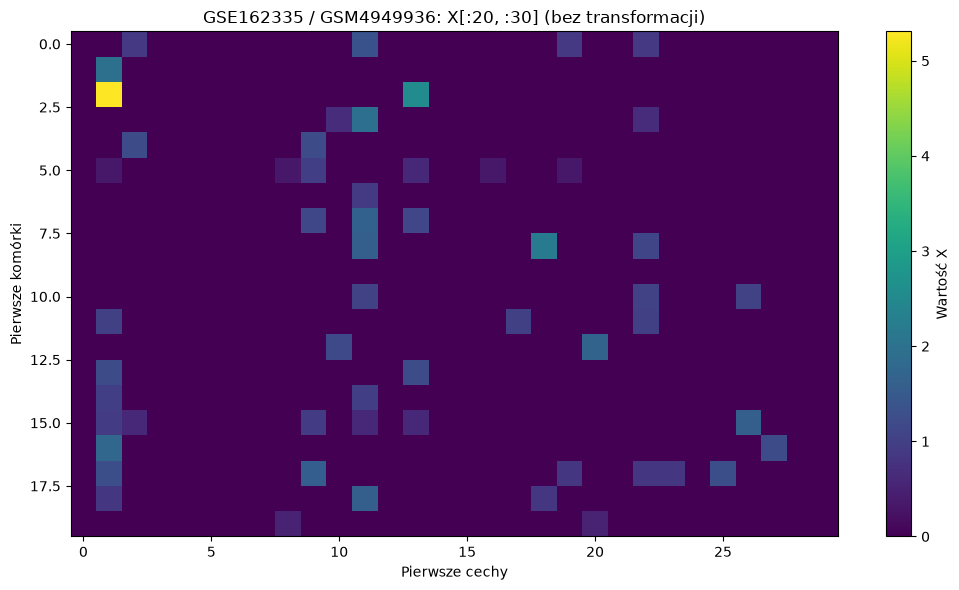


### GSE162335 / GSM4949937 — 1434 komórek × 25332 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM4949937:sh.AAACCCACACTGCATA,GSM4949937,sh.AAACCCACACTGCATA,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,1443,576,3.534
GSM4949937:sh.AAACCCATCGATCCAA,GSM4949937,sh.AAACCCATCGATCCAA,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,1260,603,5.873
GSM4949937:sh.AAACGCTCATCGTCCT,GSM4949937,sh.AAACGCTCATCGTCCT,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,4389,1323,3.828
GSM4949937:sh.AAACGCTCATCTAACG,GSM4949937,sh.AAACGCTCATCTAACG,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,2953,1016,3.048
GSM4949937:sh.AAACGCTTCCAGGACC,GSM4949937,sh.AAACGCTTCCAGGACC,<NA>,Homo sapiens,"CD45+, Colonic lamina propria",<NA>,Inflamed UC,Inflamed UC,<NA>,scRNA-seq,<NA>,GSE162335,674,361,7.567


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
7SK.1,7SK.1,<NA>,GRCh38
7SK.2,7SK.2,<NA>,GRCh38
A1BG,A1BG,<NA>,GRCh38
A1BG-AS1,A1BG-AS1,<NA>,GRCh38
A2M,A2M,<NA>,GRCh38


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE162335',
 'source_format': {'file': 'GSE162335_RAW.tar',
  'format': 'dense gene-by-cell DGE TSV in TAR',
  'member': 'GSM4949937_SingleCellCounts_UCI_11.txt.gz',
  'source_sha256': 'fcc0b11163da5b7ca68cf90e242b300c6530eb077ef0ba27e7208d346be0dc49'},
 'matrix_semantics': 'normalized',
 'feature_id_namespace': 'source-supplied symbol-like gene labels',
 'harmonization_notes': 'Loaded source normalized values without transformation; GEO documents Seurat LogNormalize (scale factor 10000). QC fields were joined by exact sample label, barcode set, and order. Source cell annotations were not copied; cell_type remains null.'}

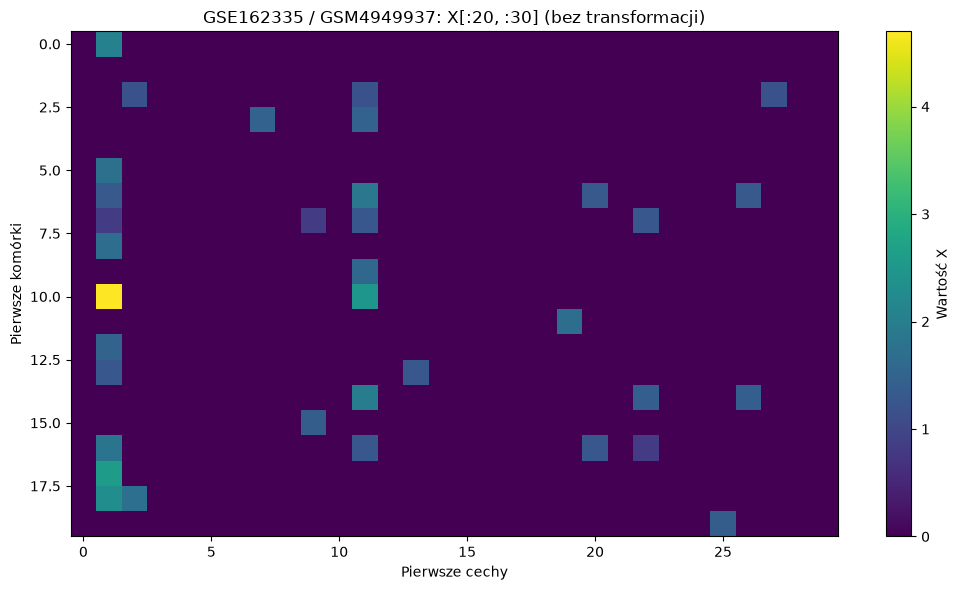


### GSE346721 / GSM10039352 — 15116 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039352:AAACCCAAGGAGGTTC-1,GSM10039352,AAACCCAAGGAGGTTC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Non-IBD Control,Non-IBD Control,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039352:AAACCCACAAATGAAC-1,GSM10039352,AAACCCACAAATGAAC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Non-IBD Control,Non-IBD Control,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039352:AAACCCACACTCACTC-1,GSM10039352,AAACCCACACTCACTC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Non-IBD Control,Non-IBD Control,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039352:AAACCCACAGCGCGTT-1,GSM10039352,AAACCCACAGCGCGTT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Non-IBD Control,Non-IBD Control,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039352:AAACCCACAGGGCTTC-1,GSM10039352,AAACCCACAGGGCTTC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Non-IBD Control,Non-IBD Control,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039352_P1_barcodes.tsv.gz',
   'features': 'GSM10039352_P1_features.tsv.gz',
   'matrix': 'GSM10039352_P1_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

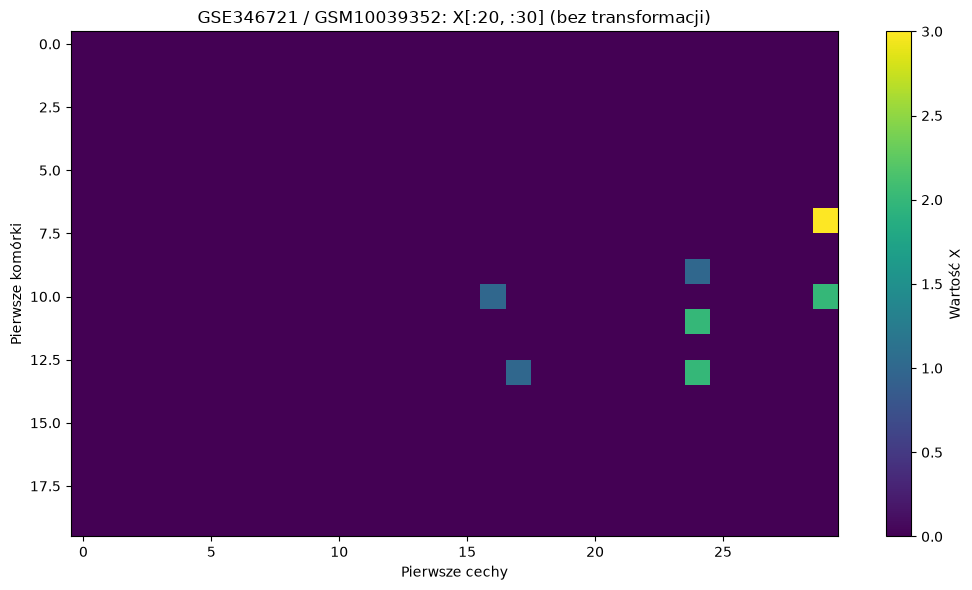


### GSE346721 / GSM10039354 — 4948 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039354:AAACCCAAGTAAGCAT-1,GSM10039354,AAACCCAAGTAAGCAT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Non-IBD Control,Non-IBD Control,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039354:AAACCCACACCCTCTA-1,GSM10039354,AAACCCACACCCTCTA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Non-IBD Control,Non-IBD Control,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039354:AAACCCACAGCTTCGG-1,GSM10039354,AAACCCACAGCTTCGG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Non-IBD Control,Non-IBD Control,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039354:AAACCCAGTGTACATC-1,GSM10039354,AAACCCAGTGTACATC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Non-IBD Control,Non-IBD Control,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039354:AAACCCAGTTGCGTAT-1,GSM10039354,AAACCCAGTTGCGTAT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Non-IBD Control,Non-IBD Control,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039354_P2_barcodes.tsv.gz',
   'features': 'GSM10039354_P2_features.tsv.gz',
   'matrix': 'GSM10039354_P2_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

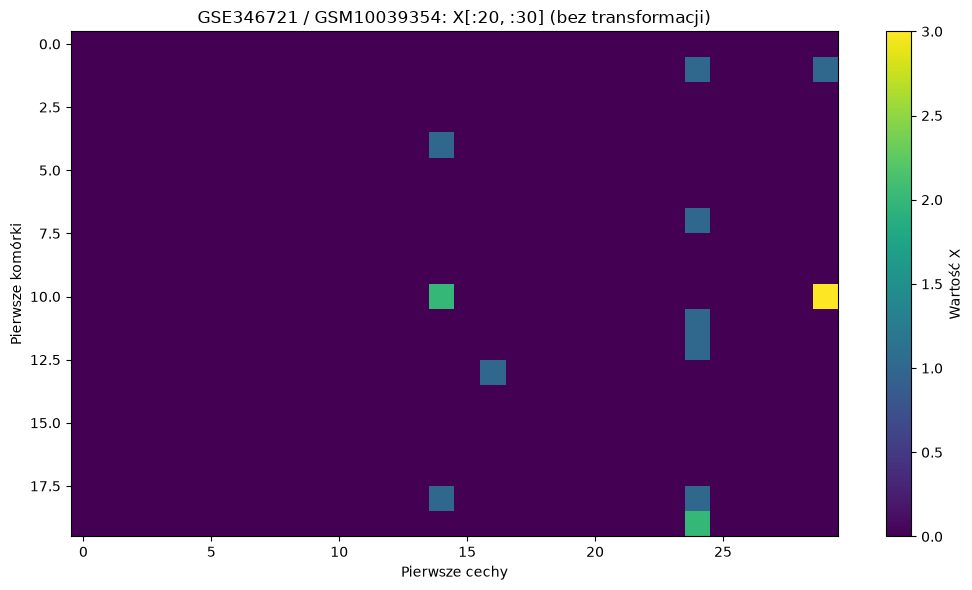


### GSE346721 / GSM10039355 — 5626 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039355:AAACCCAAGGTTCATC-1,GSM10039355,AAACCCAAGGTTCATC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Non-IBD Control,Non-IBD Control,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039355:AAACCCAGTACGATTC-1,GSM10039355,AAACCCAGTACGATTC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Non-IBD Control,Non-IBD Control,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039355:AAACCCAGTGCTAGCC-1,GSM10039355,AAACCCAGTGCTAGCC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Non-IBD Control,Non-IBD Control,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039355:AAACCCAGTGGTACAG-1,GSM10039355,AAACCCAGTGGTACAG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Non-IBD Control,Non-IBD Control,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039355:AAACCCATCGATCCAA-1,GSM10039355,AAACCCATCGATCCAA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Non-IBD Control,Non-IBD Control,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039355_P3_barcodes.tsv.gz',
   'features': 'GSM10039355_P3_features.tsv.gz',
   'matrix': 'GSM10039355_P3_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

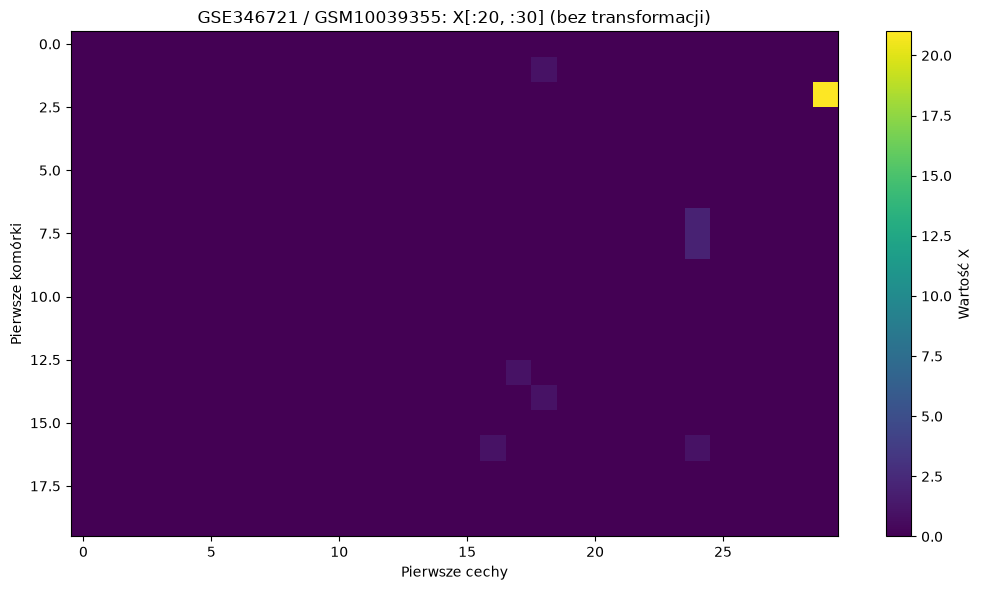


### GSE346721 / GSM10039356 — 5596 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039356:AAACCCAAGCCTAACT-1,GSM10039356,AAACCCAAGCCTAACT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Non-IBD Control,Non-IBD Control,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039356:AAACCCAAGCGATGAC-1,GSM10039356,AAACCCAAGCGATGAC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Non-IBD Control,Non-IBD Control,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039356:AAACCCACAACTGGTT-1,GSM10039356,AAACCCACAACTGGTT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Non-IBD Control,Non-IBD Control,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039356:AAACCCAGTATGCTTG-1,GSM10039356,AAACCCAGTATGCTTG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Non-IBD Control,Non-IBD Control,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039356:AAACCCATCATTGTGG-1,GSM10039356,AAACCCATCATTGTGG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Non-IBD Control,Non-IBD Control,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039356_P4_barcodes.tsv.gz',
   'features': 'GSM10039356_P4_features.tsv.gz',
   'matrix': 'GSM10039356_P4_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

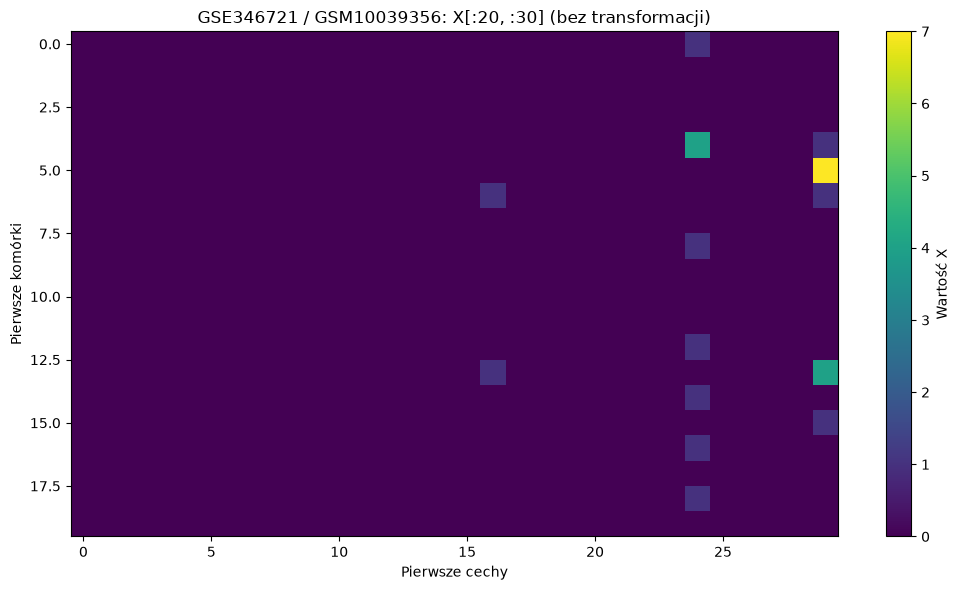


### GSE346721 / GSM10039357 — 8276 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039357:AAACCCAAGATCGACG-1,GSM10039357,AAACCCAAGATCGACG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Non-IBD Control,Non-IBD Control,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039357:AAACCCAAGGCGTTAG-1,GSM10039357,AAACCCAAGGCGTTAG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Non-IBD Control,Non-IBD Control,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039357:AAACCCACACGTTCGG-1,GSM10039357,AAACCCACACGTTCGG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Non-IBD Control,Non-IBD Control,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039357:AAACCCAGTGCCTATA-1,GSM10039357,AAACCCAGTGCCTATA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Non-IBD Control,Non-IBD Control,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039357:AAACCCATCTGGAAGG-1,GSM10039357,AAACCCATCTGGAAGG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Non-IBD Control,Non-IBD Control,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039357_P5_barcodes.tsv.gz',
   'features': 'GSM10039357_P5_features.tsv.gz',
   'matrix': 'GSM10039357_P5_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

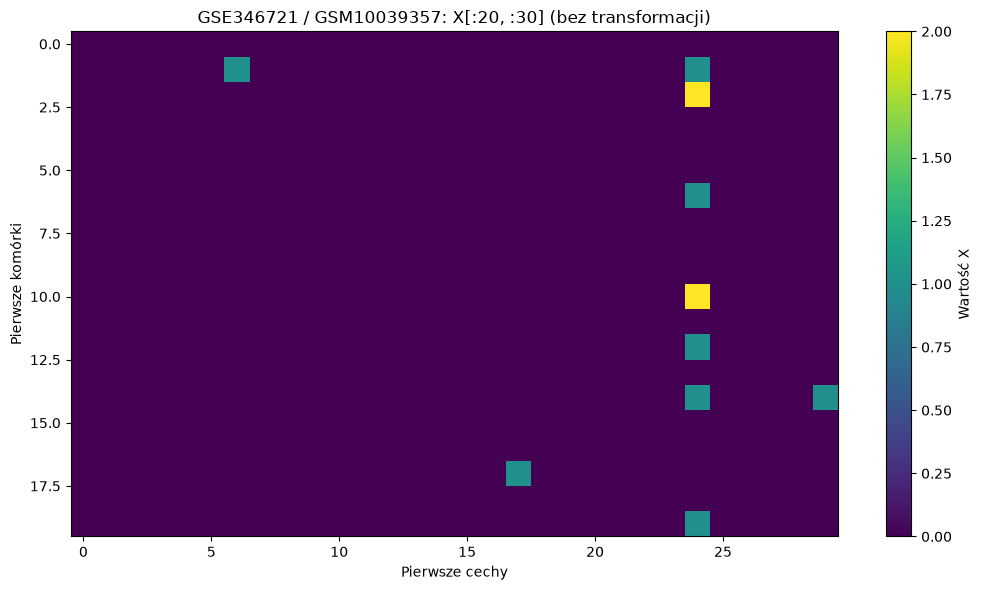


### GSE346721 / GSM10039358 — 6304 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039358:AAACCCAAGAATTTGG-1,GSM10039358,AAACCCAAGAATTTGG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Non-IBD Control,Non-IBD Control,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039358:AAACCCAAGCCGGAAT-1,GSM10039358,AAACCCAAGCCGGAAT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Non-IBD Control,Non-IBD Control,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039358:AAACCCACAATGCAAA-1,GSM10039358,AAACCCACAATGCAAA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Non-IBD Control,Non-IBD Control,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039358:AAACCCACACATATCG-1,GSM10039358,AAACCCACACATATCG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Non-IBD Control,Non-IBD Control,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039358:AAACCCAGTAGACGGT-1,GSM10039358,AAACCCAGTAGACGGT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Non-IBD Control,Non-IBD Control,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039358_P6_barcodes.tsv.gz',
   'features': 'GSM10039358_P6_features.tsv.gz',
   'matrix': 'GSM10039358_P6_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

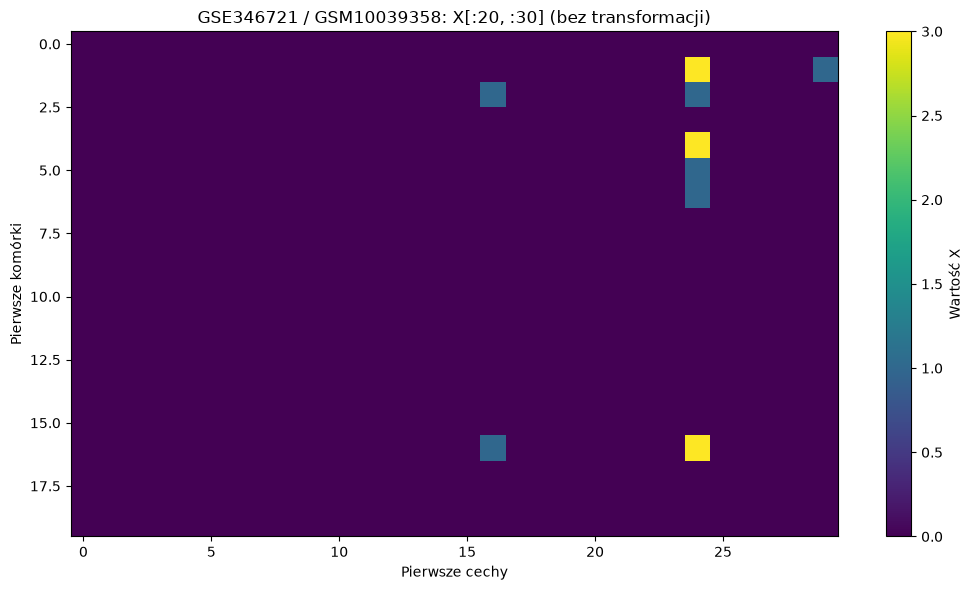


### GSE346721 / GSM10039359 — 6268 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039359:AAACCCAAGAATCGCG-1,GSM10039359,AAACCCAAGAATCGCG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Non-IBD Control,Non-IBD Control,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039359:AAACCCAAGATAGCTA-1,GSM10039359,AAACCCAAGATAGCTA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Non-IBD Control,Non-IBD Control,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039359:AAACCCAAGATTGGGC-1,GSM10039359,AAACCCAAGATTGGGC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Non-IBD Control,Non-IBD Control,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039359:AAACCCAAGCGACTGA-1,GSM10039359,AAACCCAAGCGACTGA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Non-IBD Control,Non-IBD Control,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039359:AAACCCAAGGATATGT-1,GSM10039359,AAACCCAAGGATATGT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Non-IBD Control,Non-IBD Control,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039359_P7_barcodes.tsv.gz',
   'features': 'GSM10039359_P7_features.tsv.gz',
   'matrix': 'GSM10039359_P7_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

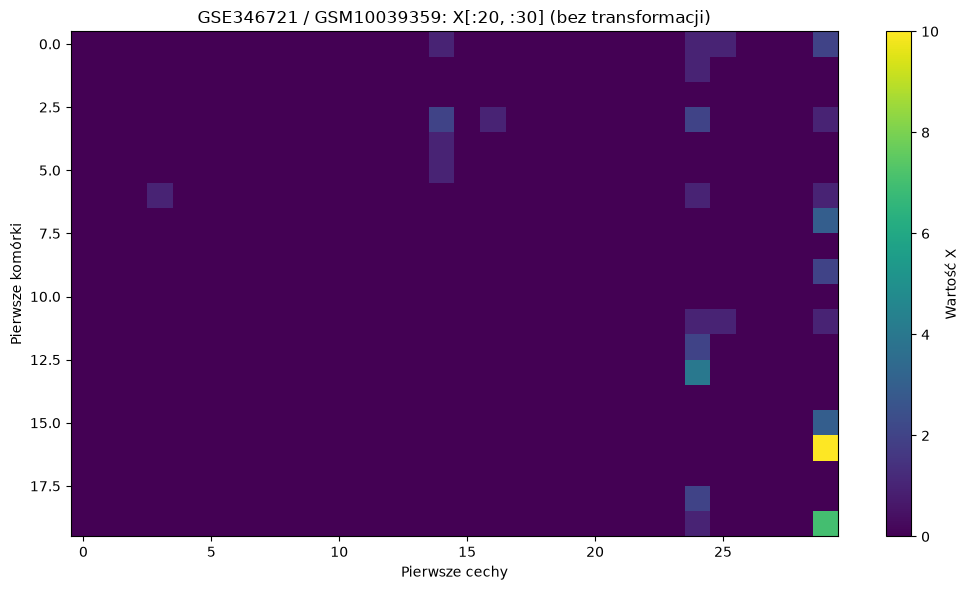


### GSE346721 / GSM10039360 — 6712 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039360:AAACCCAAGATTGCGG-1,GSM10039360,AAACCCAAGATTGCGG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039360:AAACCCAAGTTGGGAC-1,GSM10039360,AAACCCAAGTTGGGAC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039360:AAACCCACACAGAGCA-1,GSM10039360,AAACCCACACAGAGCA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039360:AAACCCAGTATCGCTA-1,GSM10039360,AAACCCAGTATCGCTA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039360:AAACCCAGTTGTCATG-1,GSM10039360,AAACCCAGTTGTCATG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039360_P8_barcodes.tsv.gz',
   'features': 'GSM10039360_P8_features.tsv.gz',
   'matrix': 'GSM10039360_P8_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

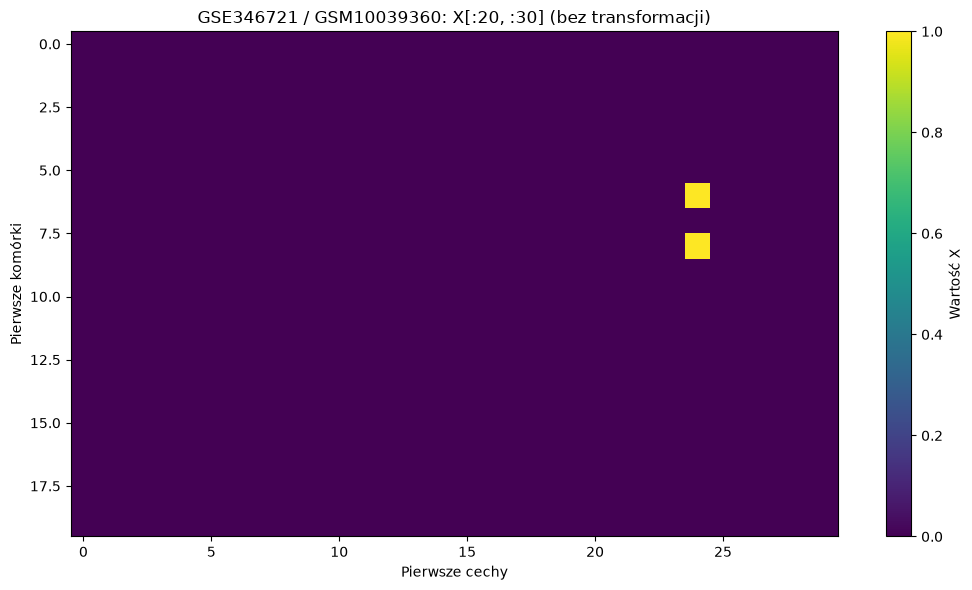


### GSE346721 / GSM10039361 — 6941 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039361:AAACCCAAGATCCCAT-1,GSM10039361,AAACCCAAGATCCCAT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039361:AAACCCACACACCGAC-1,GSM10039361,AAACCCACACACCGAC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039361:AAACCCACAGCTGTGC-1,GSM10039361,AAACCCACAGCTGTGC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039361:AAACCCACAGTGGTGA-1,GSM10039361,AAACCCACAGTGGTGA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039361:AAACCCACAGTTAAAG-1,GSM10039361,AAACCCACAGTTAAAG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039361_P9_barcodes.tsv.gz',
   'features': 'GSM10039361_P9_features.tsv.gz',
   'matrix': 'GSM10039361_P9_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

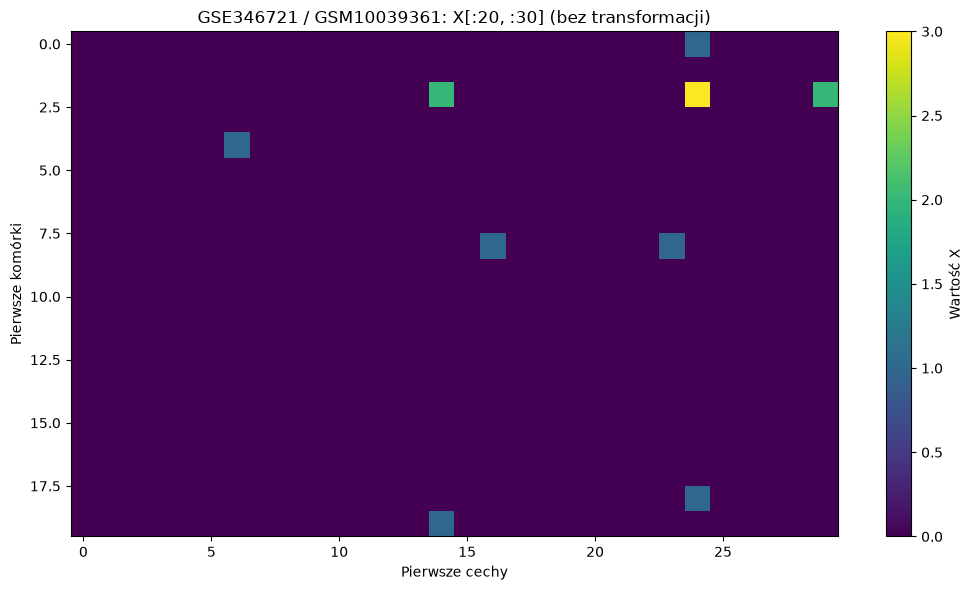


### GSE346721 / GSM10039362 — 7291 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039362:AAACCCAAGATCGCTT-1,GSM10039362,AAACCCAAGATCGCTT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039362:AAACCCAAGCCTCAAT-1,GSM10039362,AAACCCAAGCCTCAAT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039362:AAACCCAAGGATTCAA-1,GSM10039362,AAACCCAAGGATTCAA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039362:AAACCCACAATGGGTG-1,GSM10039362,AAACCCACAATGGGTG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039362:AAACCCACAGGCTCTG-1,GSM10039362,AAACCCACAGGCTCTG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039362_P10_barcodes.tsv.gz',
   'features': 'GSM10039362_P10_features.tsv.gz',
   'matrix': 'GSM10039362_P10_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

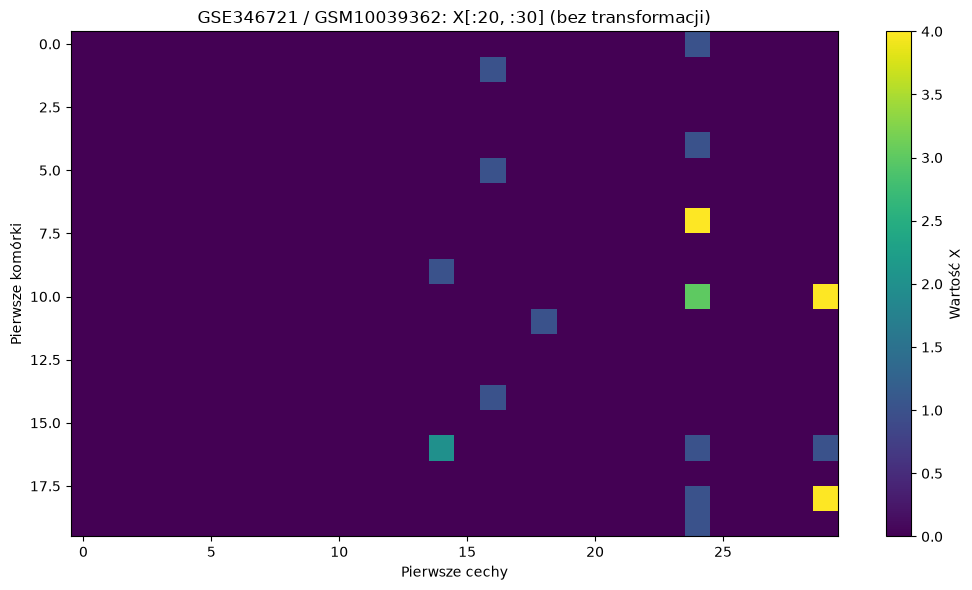


### GSE346721 / GSM10039363 — 8193 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039363:AAACCCAAGAGCACTG-1,GSM10039363,AAACCCAAGAGCACTG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039363:AAACCCAAGGTTGGTG-1,GSM10039363,AAACCCAAGGTTGGTG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039363:AAACCCACACTTGACA-1,GSM10039363,AAACCCACACTTGACA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039363:AAACCCACAGAGACTG-1,GSM10039363,AAACCCACAGAGACTG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039363:AAACCCATCCGCACTT-1,GSM10039363,AAACCCATCCGCACTT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039363_P11_barcodes.tsv.gz',
   'features': 'GSM10039363_P11_features.tsv.gz',
   'matrix': 'GSM10039363_P11_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

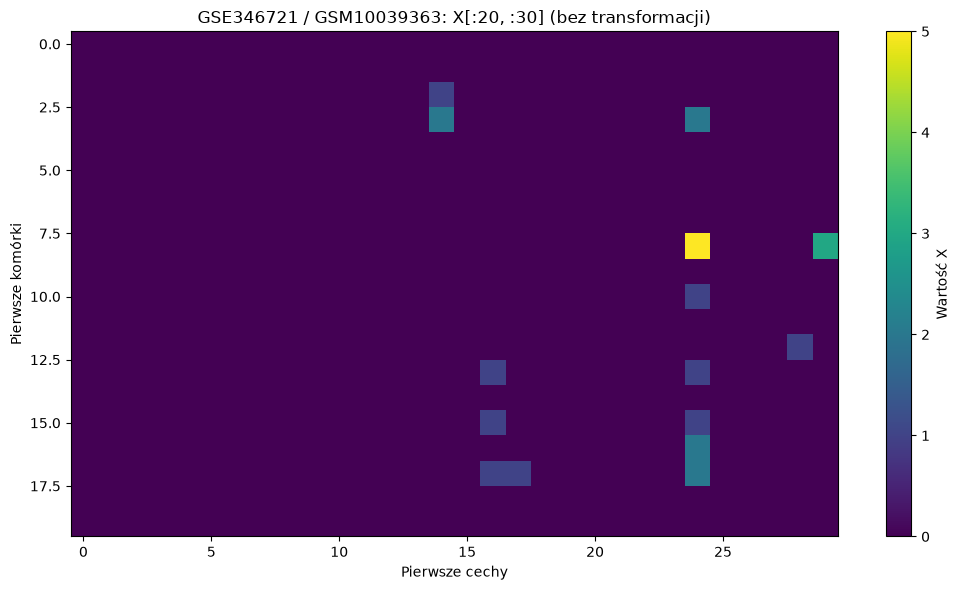


### GSE346721 / GSM10039364 — 7403 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039364:AAACCCAAGGATCATA-1,GSM10039364,AAACCCAAGGATCATA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039364:AAACCCAAGTTGTAGA-1,GSM10039364,AAACCCAAGTTGTAGA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039364:AAACCCAGTCAGGCAA-1,GSM10039364,AAACCCAGTCAGGCAA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039364:AAACCCATCACGGAGA-1,GSM10039364,AAACCCATCACGGAGA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039364:AAACCCATCCATAGGT-1,GSM10039364,AAACCCATCCATAGGT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039364_P12_barcodes.tsv.gz',
   'features': 'GSM10039364_P12_features.tsv.gz',
   'matrix': 'GSM10039364_P12_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

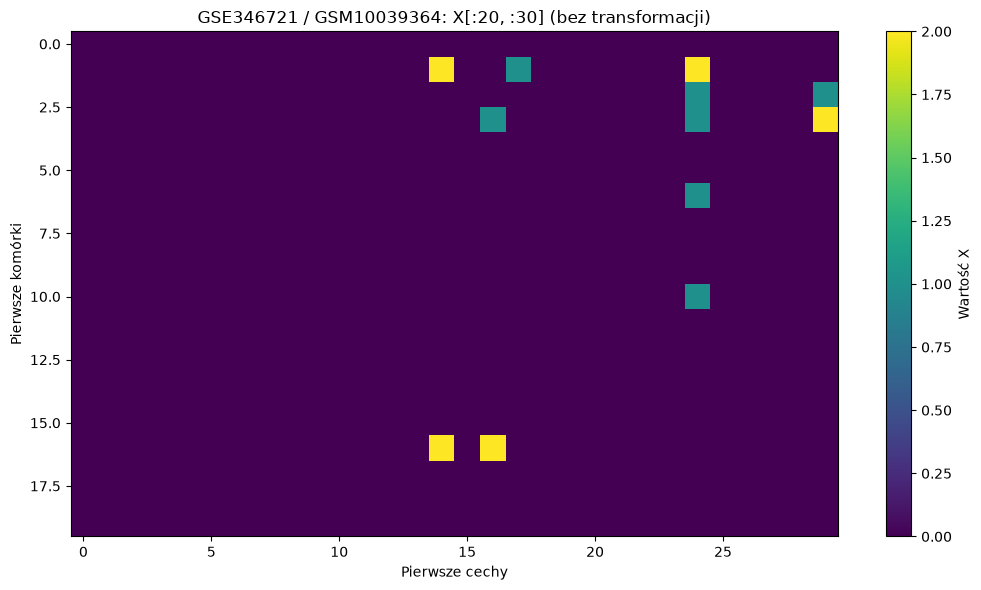


### GSE346721 / GSM10039365 — 6668 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039365:AAACCCAAGACCTGGA-1,GSM10039365,AAACCCAAGACCTGGA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039365:AAACCCAAGGAAAGTG-1,GSM10039365,AAACCCAAGGAAAGTG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039365:AAACCCAAGTTGAAGT-1,GSM10039365,AAACCCAAGTTGAAGT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039365:AAACCCACAACCGCTG-1,GSM10039365,AAACCCACAACCGCTG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039365:AAACCCACACACCGCA-1,GSM10039365,AAACCCACACACCGCA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039365_P13_barcodes.tsv.gz',
   'features': 'GSM10039365_P13_features.tsv.gz',
   'matrix': 'GSM10039365_P13_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

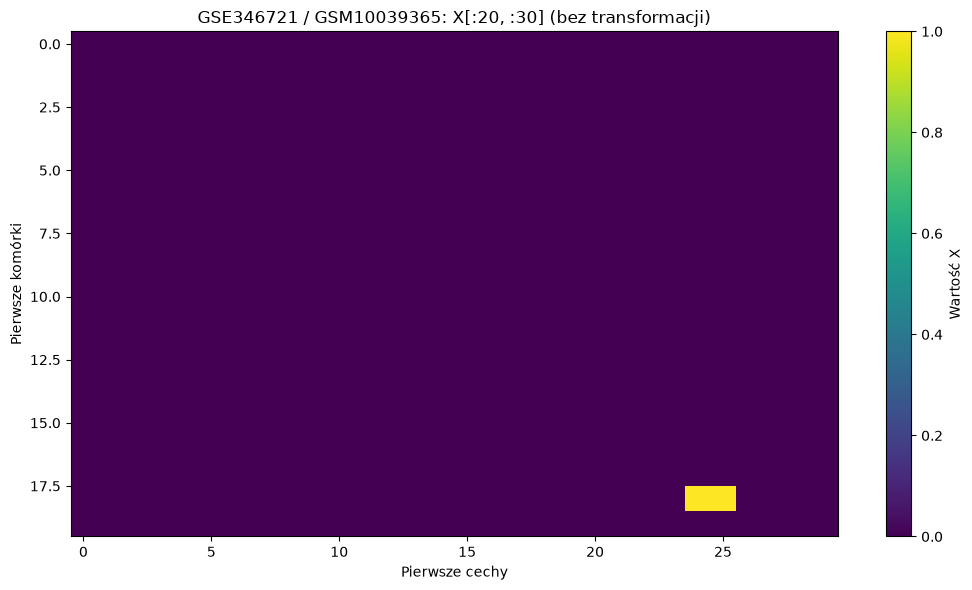


### GSE346721 / GSM10039366 — 4578 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039366:AAACCCACAATGCTCA-1,GSM10039366,AAACCCACAATGCTCA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039366:AAACCCACAGAAATTG-1,GSM10039366,AAACCCACAGAAATTG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039366:AAACGAACACAATTCG-1,GSM10039366,AAACGAACACAATTCG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039366:AAACGAAGTCCTGGGT-1,GSM10039366,AAACGAAGTCCTGGGT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039366:AAACGAATCGCCAATA-1,GSM10039366,AAACGAATCGCCAATA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039366_P14_barcodes.tsv.gz',
   'features': 'GSM10039366_P14_features.tsv.gz',
   'matrix': 'GSM10039366_P14_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

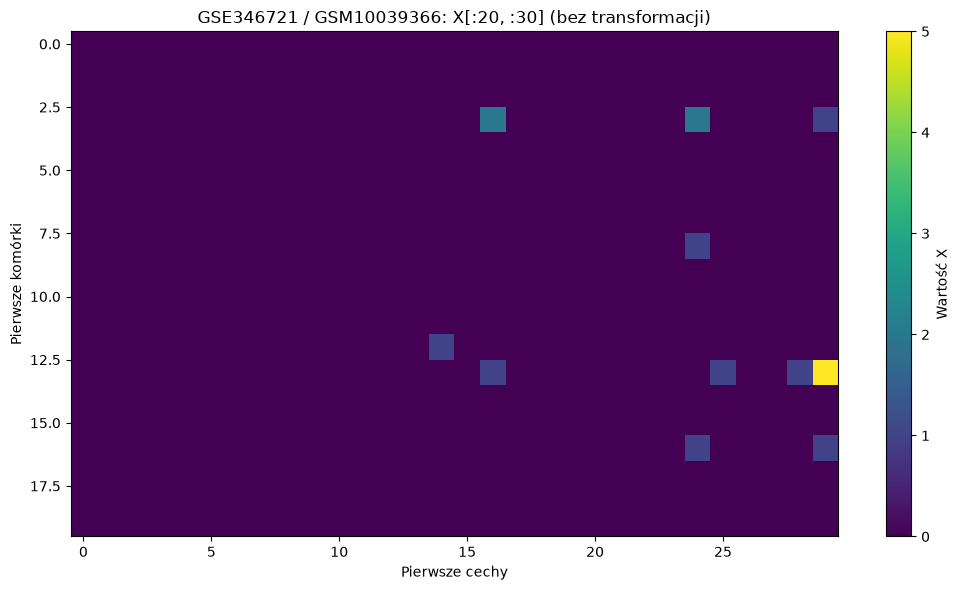


### GSE346721 / GSM10039367 — 4161 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039367:AAACCCACATGATAGA-1,GSM10039367,AAACCCACATGATAGA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039367:AAACCCAGTAGGAGTC-1,GSM10039367,AAACCCAGTAGGAGTC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039367:AAACCCAGTTTCGTAG-1,GSM10039367,AAACCCAGTTTCGTAG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039367:AAACCCATCTCTCAAT-1,GSM10039367,AAACCCATCTCTCAAT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039367:AAACGAAAGATTGACA-1,GSM10039367,AAACGAAAGATTGACA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039367_P15_barcodes.tsv.gz',
   'features': 'GSM10039367_P15_features.tsv.gz',
   'matrix': 'GSM10039367_P15_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

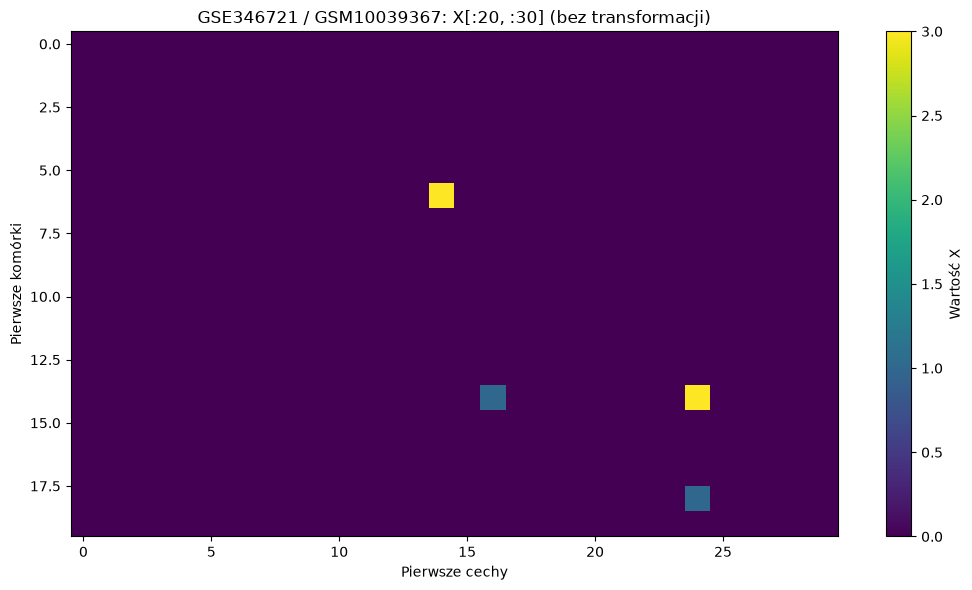


### GSE346721 / GSM10039368 — 7895 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039368:AAACCCACAATCGCGC-1,GSM10039368,AAACCCACAATCGCGC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039368:AAACCCACACCCATAA-1,GSM10039368,AAACCCACACCCATAA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039368:AAACCCACAGAAGCGT-1,GSM10039368,AAACCCACAGAAGCGT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039368:AAACCCACAGTAGTGG-1,GSM10039368,AAACCCACAGTAGTGG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039368:AAACCCAGTGATCGTT-1,GSM10039368,AAACCCAGTGATCGTT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039368_P16_barcodes.tsv.gz',
   'features': 'GSM10039368_P16_features.tsv.gz',
   'matrix': 'GSM10039368_P16_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

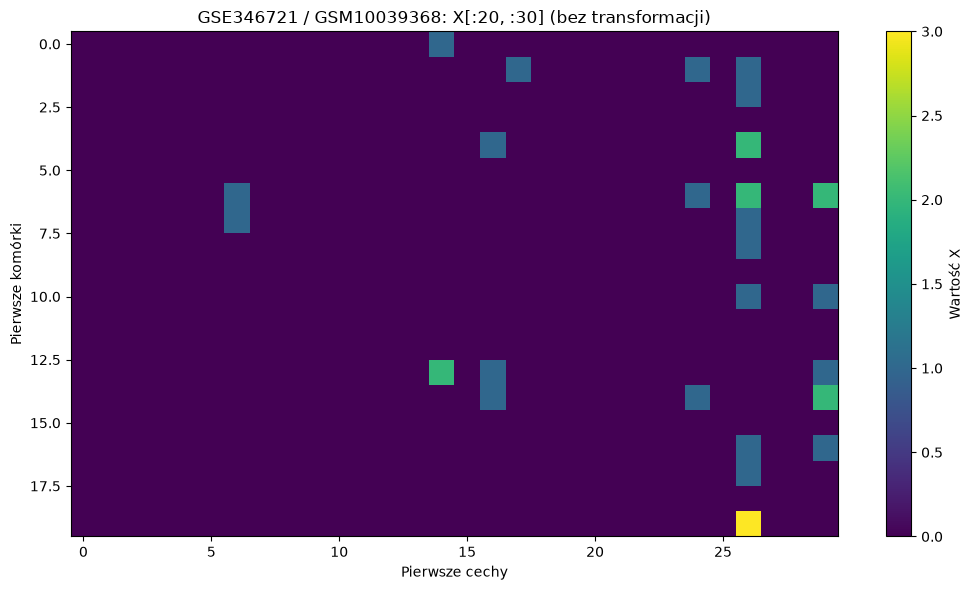


### GSE346721 / GSM10039369 — 6934 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039369:AAACCCAAGGAATCGC-1,GSM10039369,AAACCCAAGGAATCGC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039369:AAACCCAAGTTGGGAC-1,GSM10039369,AAACCCAAGTTGGGAC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039369:AAACCCACAACACAGG-1,GSM10039369,AAACCCACAACACAGG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039369:AAACCCACATCAGTCA-1,GSM10039369,AAACCCACATCAGTCA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039369:AAACCCACATCTATCT-1,GSM10039369,AAACCCACATCTATCT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039369_P17_barcodes.tsv.gz',
   'features': 'GSM10039369_P17_features.tsv.gz',
   'matrix': 'GSM10039369_P17_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

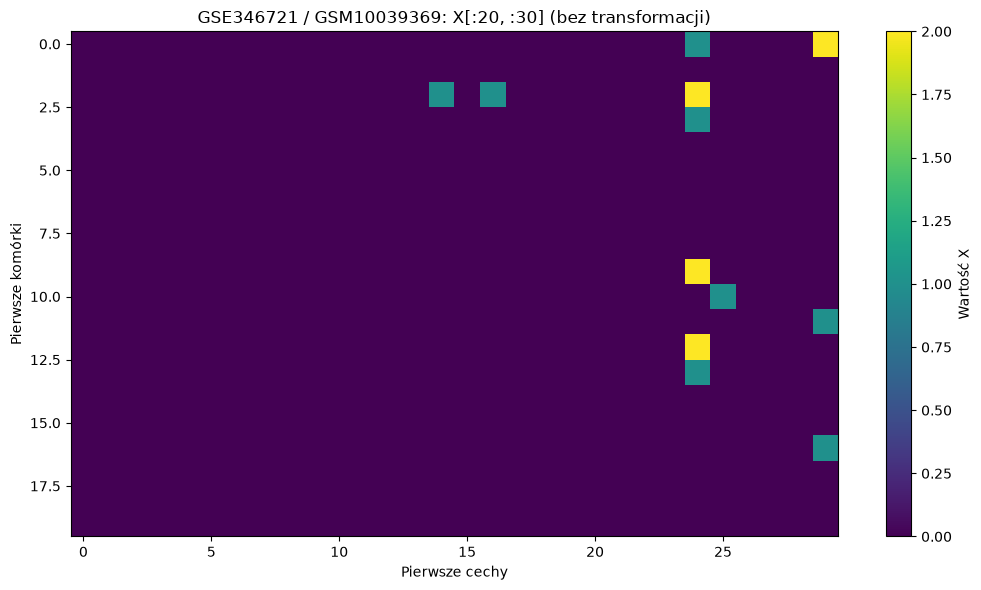


### GSE346721 / GSM10039370 — 5939 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039370:AAACCCAAGCCAGAGT-1,GSM10039370,AAACCCAAGCCAGAGT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039370:AAACCCACACCGGAAA-1,GSM10039370,AAACCCACACCGGAAA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039370:AAACCCACAGATTAAG-1,GSM10039370,AAACCCACAGATTAAG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039370:AAACCCAGTATAGGAT-1,GSM10039370,AAACCCAGTATAGGAT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039370:AAACCCATCACTGGGC-1,GSM10039370,AAACCCATCACTGGGC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039370_P18_barcodes.tsv.gz',
   'features': 'GSM10039370_P18_features.tsv.gz',
   'matrix': 'GSM10039370_P18_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

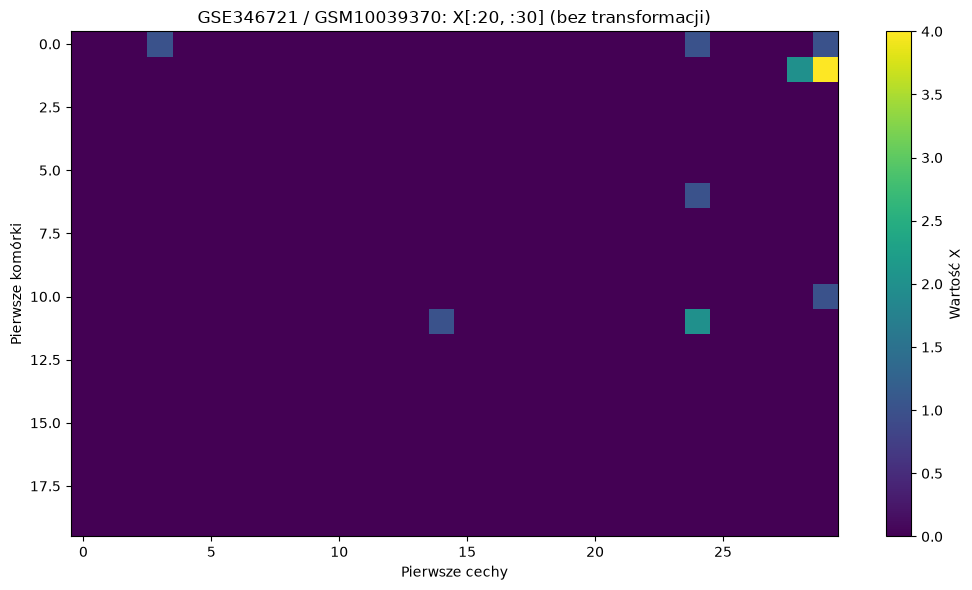


### GSE346721 / GSM10039371 — 2916 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039371:AAACCCACAGCTTTCC-1,GSM10039371,AAACCCACAGCTTTCC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039371:AAACCCATCCATTTAC-1,GSM10039371,AAACCCATCCATTTAC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039371:AAACCCATCTACACAG-1,GSM10039371,AAACCCATCTACACAG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039371:AAACGAAGTTCCGCTT-1,GSM10039371,AAACGAAGTTCCGCTT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039371:AAACGAAGTTCGTGCG-1,GSM10039371,AAACGAAGTTCGTGCG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039371_P19_barcodes.tsv.gz',
   'features': 'GSM10039371_P19_features.tsv.gz',
   'matrix': 'GSM10039371_P19_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

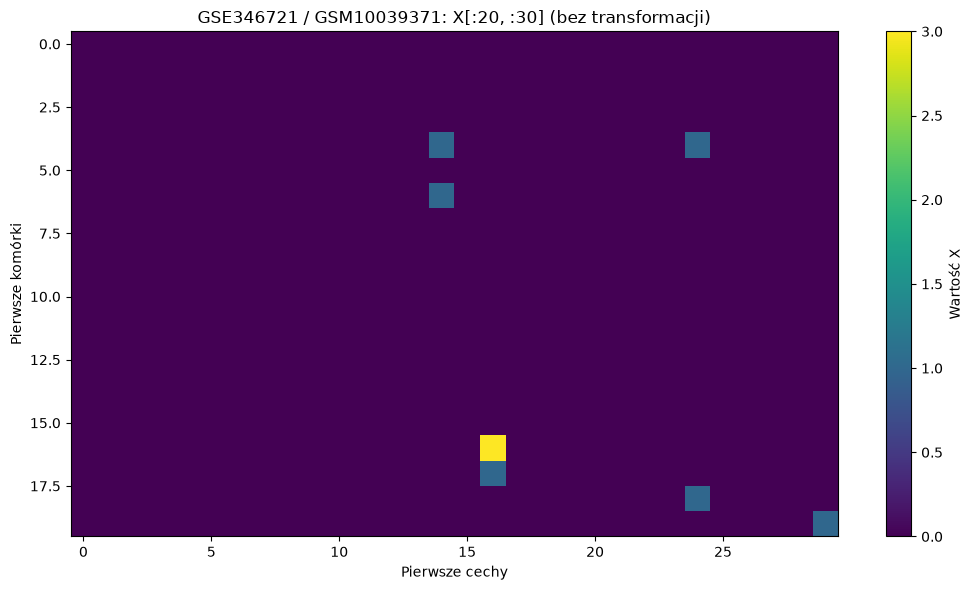


### GSE346721 / GSM10039372 — 3309 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039372:AAACCCAAGGACGGAG-1,GSM10039372,AAACCCAAGGACGGAG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039372:AAACCCACAGGGAGAG-1,GSM10039372,AAACCCACAGGGAGAG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039372:AAACCCATCCGAGATT-1,GSM10039372,AAACCCATCCGAGATT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039372:AAACCCATCCTACCGT-1,GSM10039372,AAACCCATCCTACCGT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039372:AAACCCATCCTGCCAT-1,GSM10039372,AAACCCATCCTGCCAT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039372_P20_barcodes.tsv.gz',
   'features': 'GSM10039372_P20_features.tsv.gz',
   'matrix': 'GSM10039372_P20_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

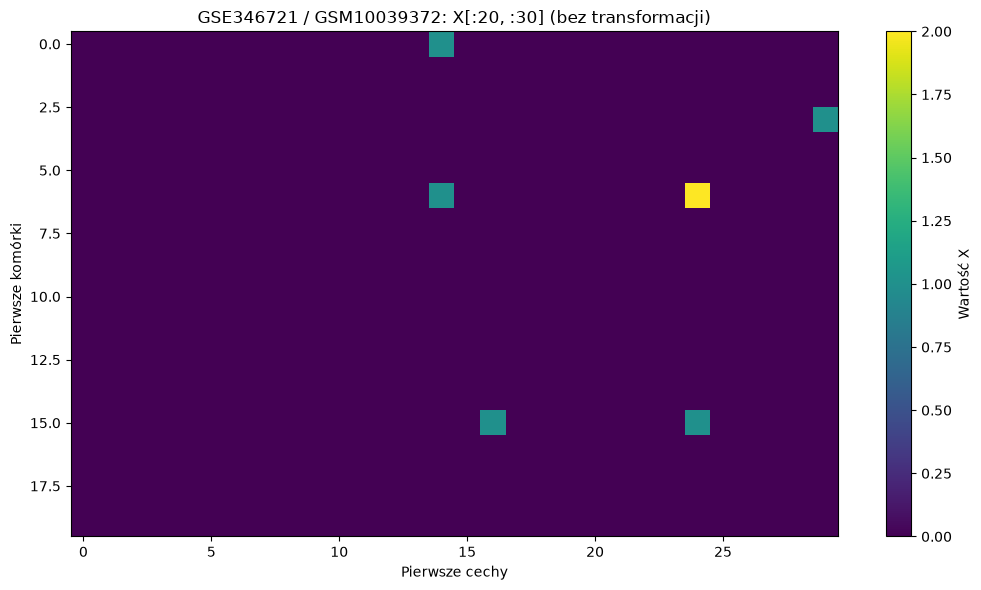


### GSE346721 / GSM10039373 — 3055 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039373:AAACCCAAGTCCCTAA-1,GSM10039373,AAACCCAAGTCCCTAA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039373:AAACCCACAGCCCAGT-1,GSM10039373,AAACCCACAGCCCAGT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039373:AAACCCAGTGCGCTCA-1,GSM10039373,AAACCCAGTGCGCTCA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039373:AAACGAAAGGCCACTC-1,GSM10039373,AAACGAAAGGCCACTC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039373:AAACGAAGTTTACTGG-1,GSM10039373,AAACGAAGTTTACTGG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039373_P21_barcodes.tsv.gz',
   'features': 'GSM10039373_P21_features.tsv.gz',
   'matrix': 'GSM10039373_P21_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

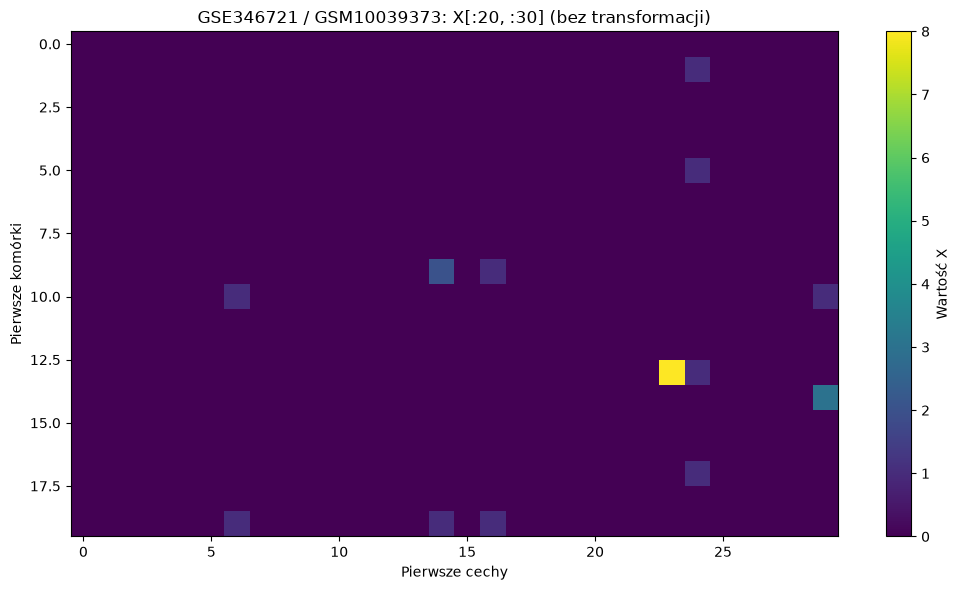


### GSE346721 / GSM10039374 — 4705 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039374:AAACCCAAGACGTCCC-1,GSM10039374,AAACCCAAGACGTCCC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039374:AAACCCAAGCTTCATG-1,GSM10039374,AAACCCAAGCTTCATG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039374:AAACCCACACGTTCGG-1,GSM10039374,AAACCCACACGTTCGG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039374:AAACCCAGTAGGCTCC-1,GSM10039374,AAACCCAGTAGGCTCC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039374:AAACCCAGTTCGTGCG-1,GSM10039374,AAACCCAGTTCGTGCG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039374_P22_barcodes.tsv.gz',
   'features': 'GSM10039374_P22_features.tsv.gz',
   'matrix': 'GSM10039374_P22_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

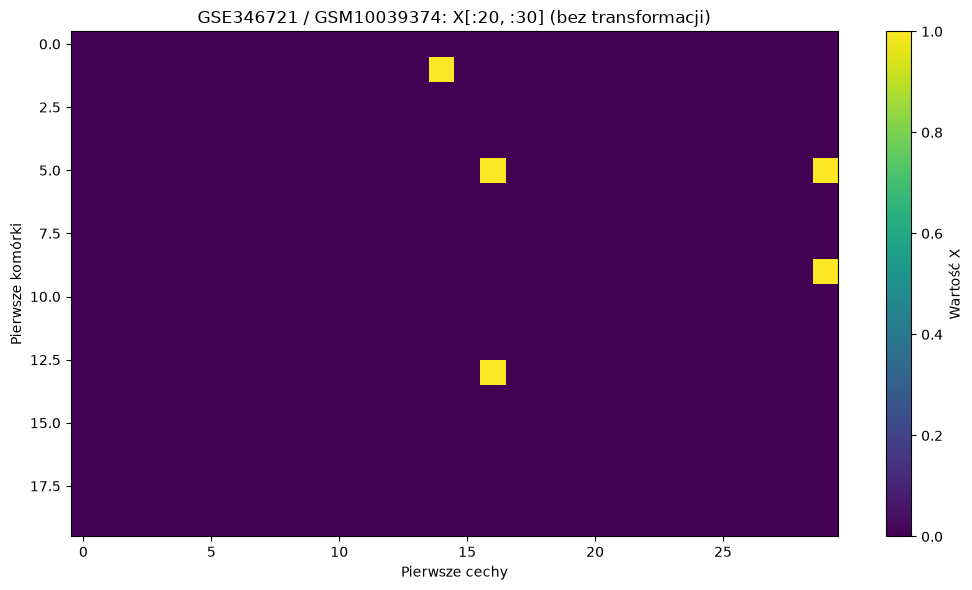


### GSE346721 / GSM10039375 — 4820 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039375:AAACCCAAGCTGAAGC-1,GSM10039375,AAACCCAAGCTGAAGC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039375:AAACCCACAAGAATGT-1,GSM10039375,AAACCCACAAGAATGT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039375:AAACCCACATCGATCA-1,GSM10039375,AAACCCACATCGATCA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039375:AAACCCACATGGCTGC-1,GSM10039375,AAACCCACATGGCTGC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039375:AAACCCAGTCCGACGT-1,GSM10039375,AAACCCAGTCCGACGT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039375_P23_barcodes.tsv.gz',
   'features': 'GSM10039375_P23_features.tsv.gz',
   'matrix': 'GSM10039375_P23_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

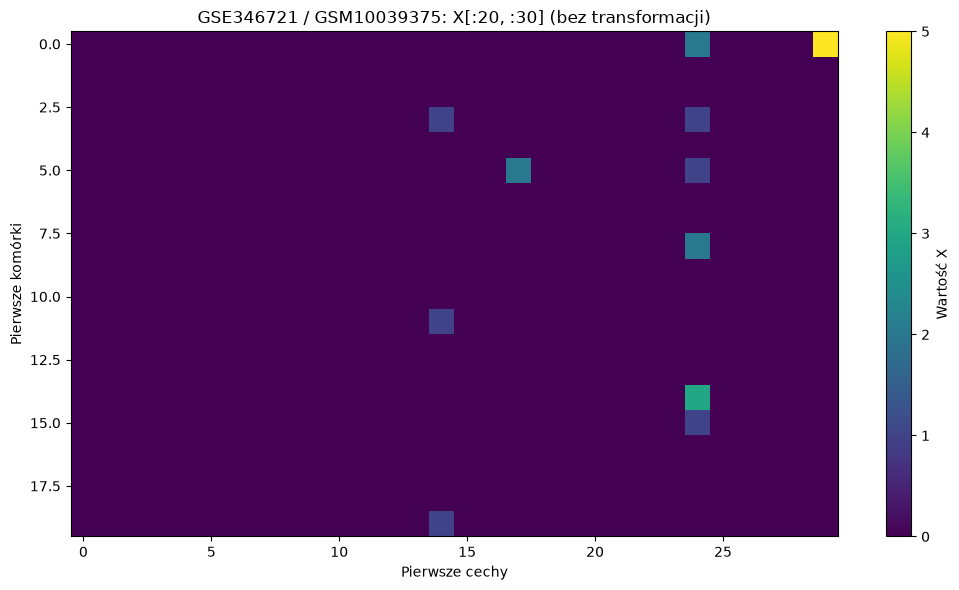


### GSE346721 / GSM10039376 — 3598 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039376:AAACCCACACTACTTT-1,GSM10039376,AAACCCACACTACTTT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039376:AAACCCACATCTCAAG-1,GSM10039376,AAACCCACATCTCAAG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039376:AAACCCATCGAGCTGC-1,GSM10039376,AAACCCATCGAGCTGC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039376:AAACCCATCGCACGGT-1,GSM10039376,AAACCCATCGCACGGT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039376:AAACGAAGTGAATTAG-1,GSM10039376,AAACGAAGTGAATTAG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039376_P24_barcodes.tsv.gz',
   'features': 'GSM10039376_P24_features.tsv.gz',
   'matrix': 'GSM10039376_P24_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

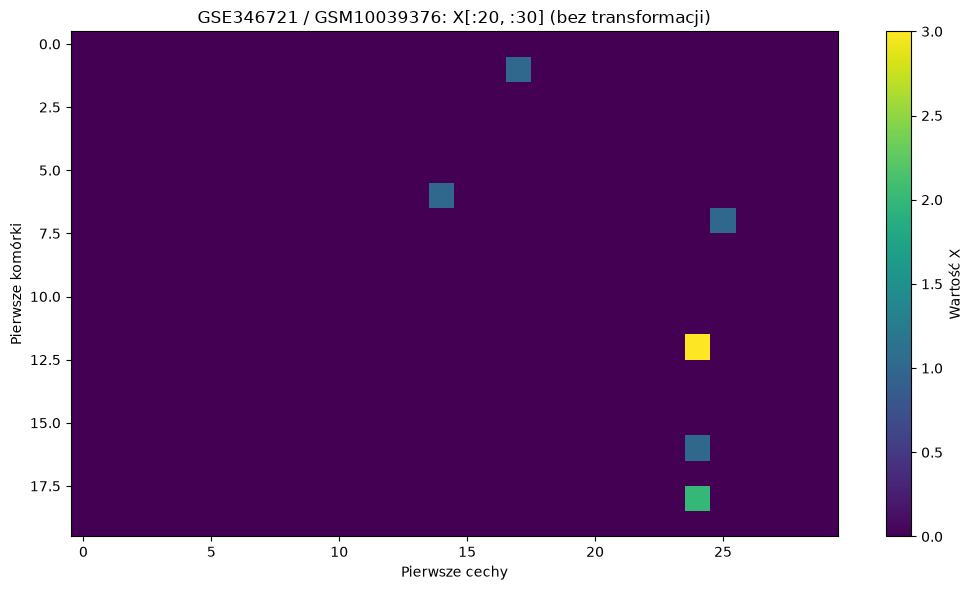


### GSE346721 / GSM10039377 — 1814 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039377:AAACCCACAGCACAGA-1,GSM10039377,AAACCCACAGCACAGA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039377:AAACCCAGTGTTCGAT-1,GSM10039377,AAACCCAGTGTTCGAT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039377:AAACGAAGTAAGGTCG-1,GSM10039377,AAACGAAGTAAGGTCG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039377:AAACGAATCCTGTACC-1,GSM10039377,AAACGAATCCTGTACC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039377:AAACGCTAGCATGGGT-1,GSM10039377,AAACGCTAGCATGGGT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039377_P25_barcodes.tsv.gz',
   'features': 'GSM10039377_P25_features.tsv.gz',
   'matrix': 'GSM10039377_P25_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

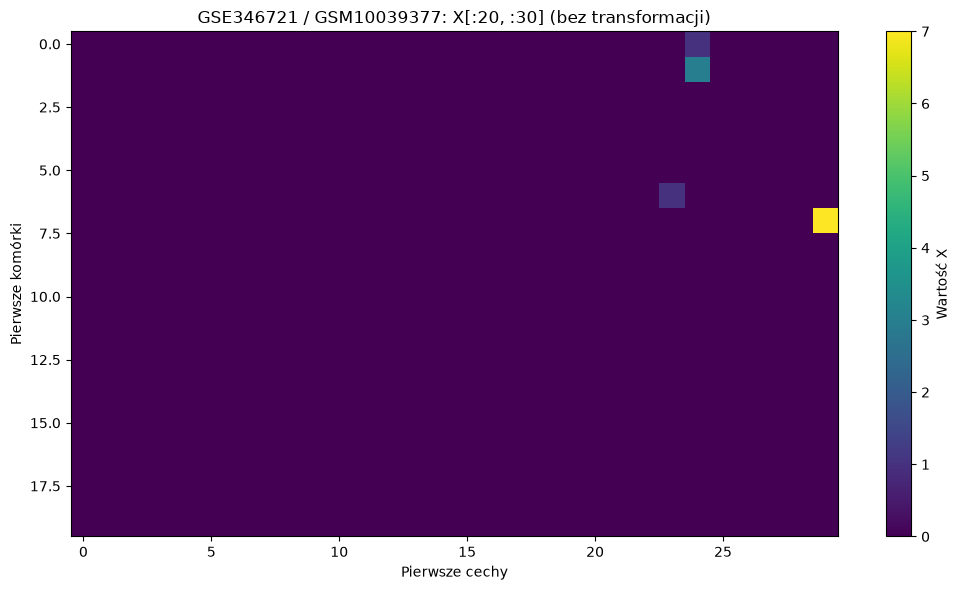


### GSE346721 / GSM10039378 — 2491 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039378:AAACCCACAAAGACGC-1,GSM10039378,AAACCCACAAAGACGC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039378:AAACCCACACTTACAG-1,GSM10039378,AAACCCACACTTACAG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039378:AAACCCAGTTGTTGAC-1,GSM10039378,AAACCCAGTTGTTGAC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039378:AAACGAACATAGGCGA-1,GSM10039378,AAACGAACATAGGCGA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039378:AAACGAAGTGCTGATT-1,GSM10039378,AAACGAAGTGCTGATT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039378_P26_barcodes.tsv.gz',
   'features': 'GSM10039378_P26_features.tsv.gz',
   'matrix': 'GSM10039378_P26_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

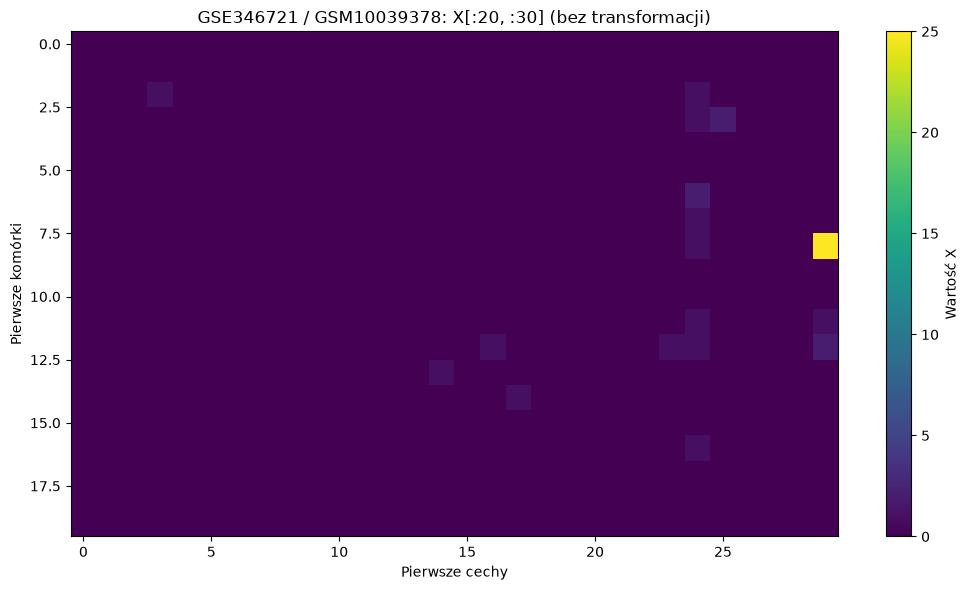


### GSE346721 / GSM10039379 — 9762 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039379:AAACCCAAGACATGCG-1,GSM10039379,AAACCCAAGACATGCG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039379:AAACCCAAGAGGGTGG-1,GSM10039379,AAACCCAAGAGGGTGG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039379:AAACCCAAGGCACGAT-1,GSM10039379,AAACCCAAGGCACGAT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039379:AAACCCACACCAGCTG-1,GSM10039379,AAACCCACACCAGCTG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039379:AAACCCACAGAAGTGC-1,GSM10039379,AAACCCACAGAAGTGC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Treatment-naïve Crohn's disease,Treatment-naïve Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039379_P27_barcodes.tsv.gz',
   'features': 'GSM10039379_P27_features.tsv.gz',
   'matrix': 'GSM10039379_P27_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

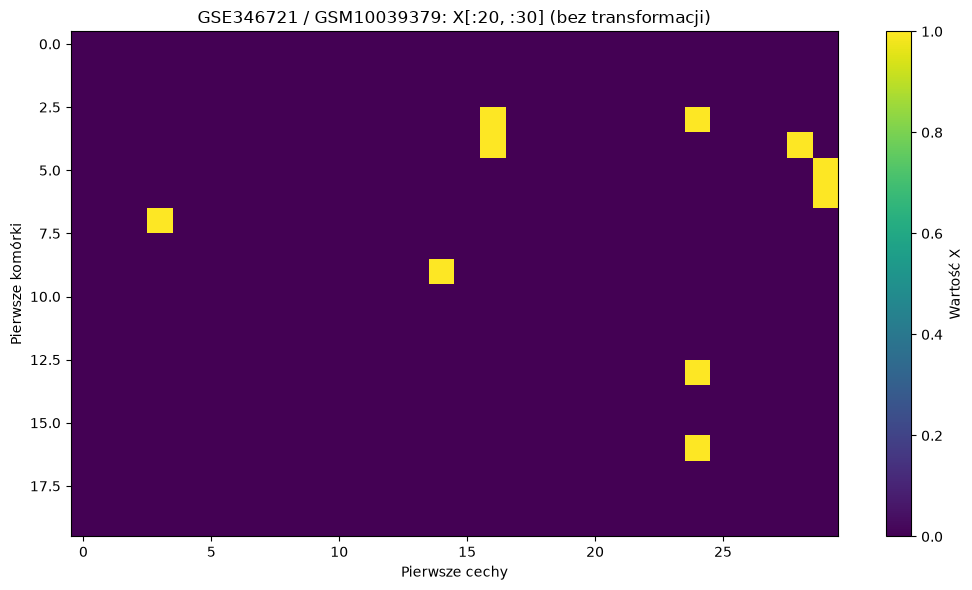


### GSE346721 / GSM10039380 — 6827 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039380:AAACCCAAGCATTTCG-1,GSM10039380,AAACCCAAGCATTTCG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Established Crohn's disease,Established Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039380:AAACCCAAGCGCAATG-1,GSM10039380,AAACCCAAGCGCAATG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Established Crohn's disease,Established Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039380:AAACCCAAGCGCCATC-1,GSM10039380,AAACCCAAGCGCCATC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Established Crohn's disease,Established Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039380:AAACCCAAGGTAAGGA-1,GSM10039380,AAACCCAAGGTAAGGA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Established Crohn's disease,Established Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039380:AAACCCAAGTTCGGTT-1,GSM10039380,AAACCCAAGTTCGGTT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Established Crohn's disease,Established Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039380_P28_barcodes.tsv.gz',
   'features': 'GSM10039380_P28_features.tsv.gz',
   'matrix': 'GSM10039380_P28_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

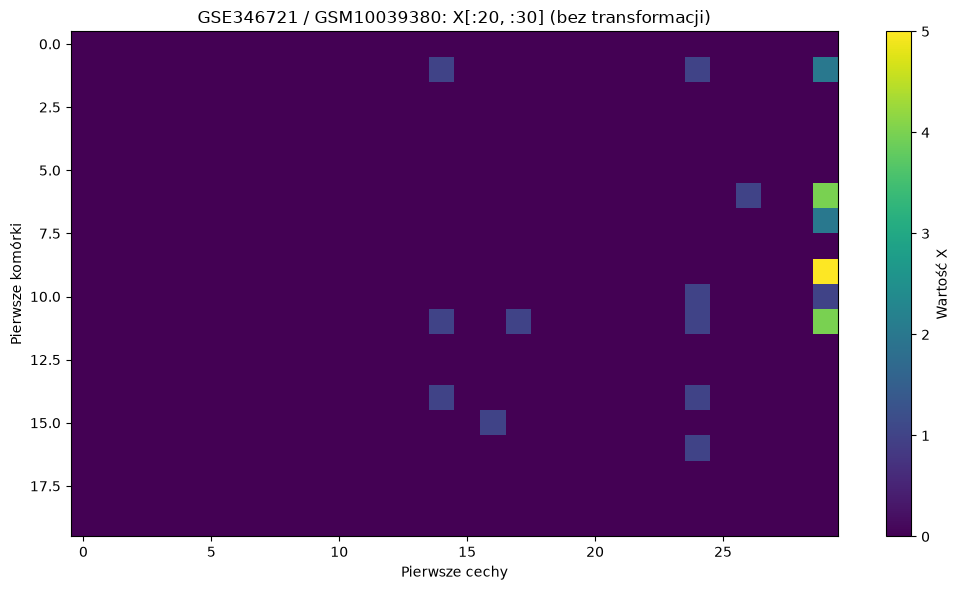


### GSE346721 / GSM10039381 — 3078 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039381:AAACCCAAGCAGGCTA-1,GSM10039381,AAACCCAAGCAGGCTA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Established Crohn's disease,Established Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039381:AAACCCACACCGGCTA-1,GSM10039381,AAACCCACACCGGCTA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Established Crohn's disease,Established Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039381:AAACCCACACGCCAGT-1,GSM10039381,AAACCCACACGCCAGT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Established Crohn's disease,Established Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039381:AAACGAAAGAGAATCT-1,GSM10039381,AAACGAAAGAGAATCT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Established Crohn's disease,Established Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039381:AAACGAAAGAGGTTTA-1,GSM10039381,AAACGAAAGAGGTTTA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Established Crohn's disease,Established Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039381_P29_barcodes.tsv.gz',
   'features': 'GSM10039381_P29_features.tsv.gz',
   'matrix': 'GSM10039381_P29_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

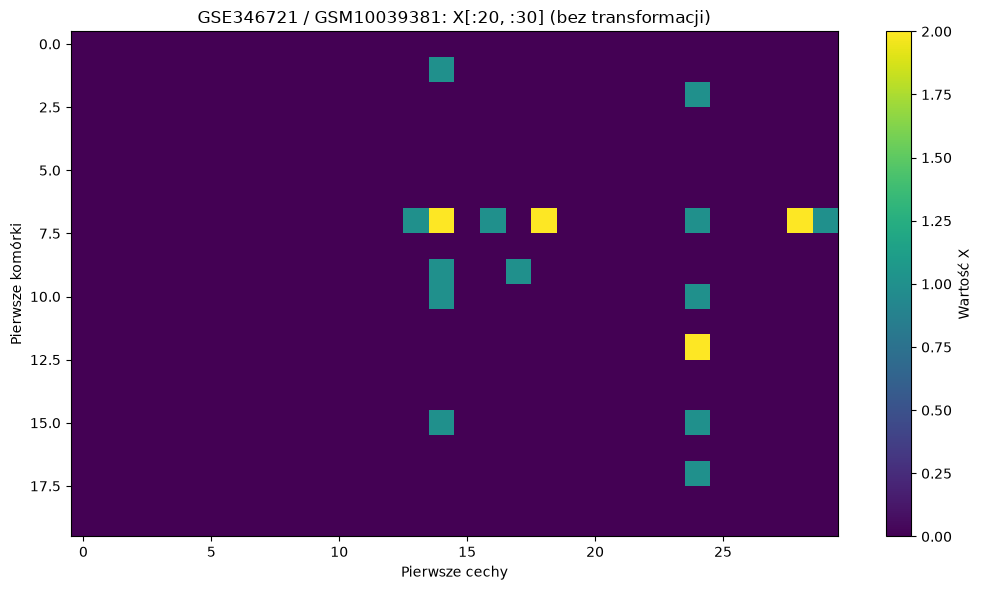


### GSE346721 / GSM10039382 — 4111 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039382:AAACCCAAGACTCTTG-1,GSM10039382,AAACCCAAGACTCTTG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Established Crohn's disease,Established Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039382:AAACCCAAGCCTCAAT-1,GSM10039382,AAACCCAAGCCTCAAT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Established Crohn's disease,Established Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039382:AAACCCAGTAAGACCG-1,GSM10039382,AAACCCAGTAAGACCG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Established Crohn's disease,Established Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039382:AAACCCATCAAGCGTT-1,GSM10039382,AAACCCATCAAGCGTT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Established Crohn's disease,Established Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039382:AAACCCATCGAATGCT-1,GSM10039382,AAACCCATCGAATGCT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Established Crohn's disease,Established Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039382_P30_barcodes.tsv.gz',
   'features': 'GSM10039382_P30_features.tsv.gz',
   'matrix': 'GSM10039382_P30_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

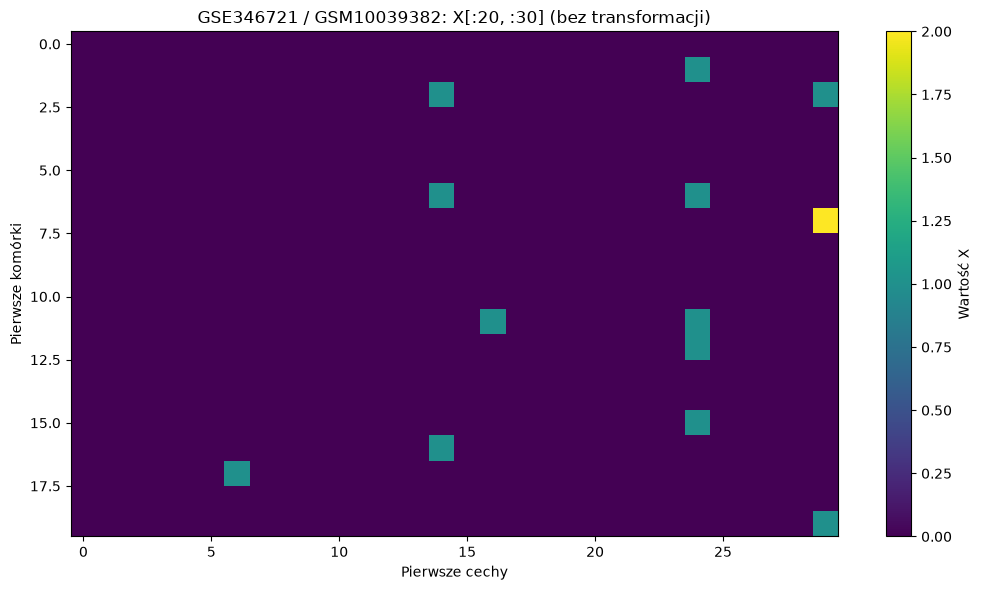


### GSE346721 / GSM10039383 — 6401 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039383:AAACCCAAGAGAGGGC-1,GSM10039383,AAACCCAAGAGAGGGC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Established Crohn's disease,Established Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039383:AAACCCACAAGTTGGG-1,GSM10039383,AAACCCACAAGTTGGG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Established Crohn's disease,Established Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039383:AAACCCAGTTCATCGA-1,GSM10039383,AAACCCAGTTCATCGA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Established Crohn's disease,Established Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039383:AAACCCAGTTTAGTCG-1,GSM10039383,AAACCCAGTTTAGTCG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Established Crohn's disease,Established Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039383:AAACGAAAGCTGGTGA-1,GSM10039383,AAACGAAAGCTGGTGA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Established Crohn's disease,Established Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039383_P31_barcodes.tsv.gz',
   'features': 'GSM10039383_P31_features.tsv.gz',
   'matrix': 'GSM10039383_P31_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

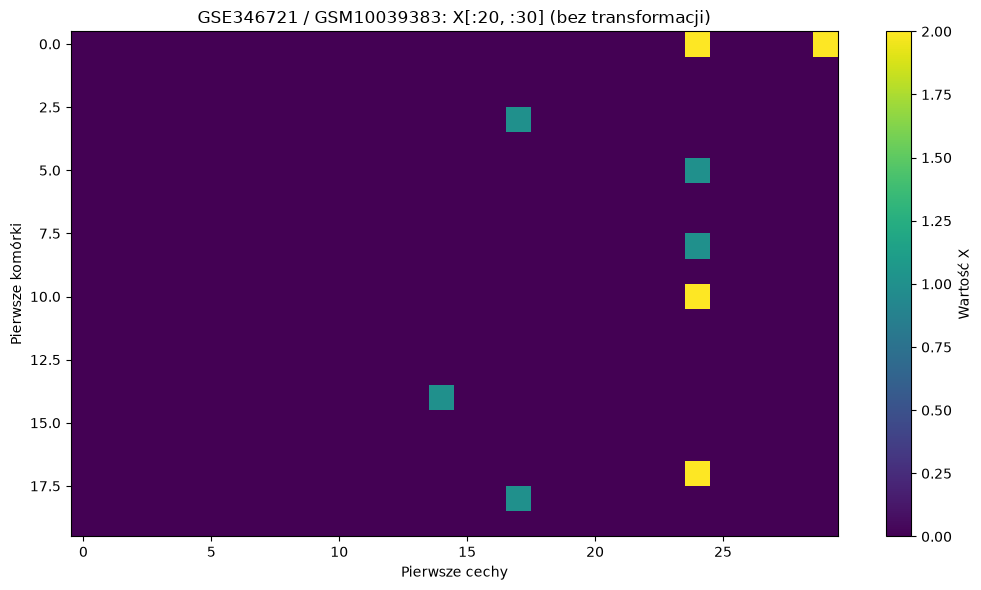


### GSE346721 / GSM10039384 — 10761 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039384:AAACCCAAGAAATTCG-1,GSM10039384,AAACCCAAGAAATTCG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Established Crohn's disease,Established Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039384:AAACCCAAGACGACTG-1,GSM10039384,AAACCCAAGACGACTG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Established Crohn's disease,Established Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039384:AAACCCAAGCTTCATG-1,GSM10039384,AAACCCAAGCTTCATG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Established Crohn's disease,Established Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039384:AAACCCAAGGCCCGTT-1,GSM10039384,AAACCCAAGGCCCGTT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Established Crohn's disease,Established Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039384:AAACCCAAGTATGTAG-1,GSM10039384,AAACCCAAGTATGTAG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Established Crohn's disease,Established Crohn's disease,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039384_P32_barcodes.tsv.gz',
   'features': 'GSM10039384_P32_features.tsv.gz',
   'matrix': 'GSM10039384_P32_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

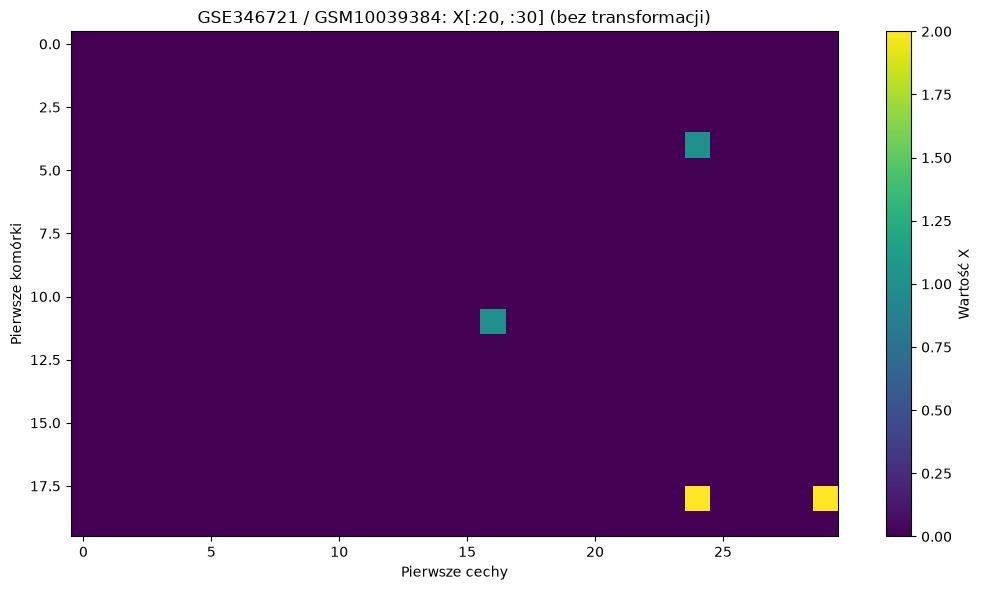


### GSE346721 / GSM10039385 — 6031 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039385:AAACCCAAGAGCGACT-1,GSM10039385,AAACCCAAGAGCGACT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039385:AAACCCAAGCAACAAT-1,GSM10039385,AAACCCAAGCAACAAT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039385:AAACCCACAAGGGTCA-1,GSM10039385,AAACCCACAAGGGTCA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039385:AAACCCACACAACGCC-1,GSM10039385,AAACCCACACAACGCC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039385:AAACCCACAGCAGTAG-1,GSM10039385,AAACCCACAGCAGTAG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039385_P33_barcodes.tsv.gz',
   'features': 'GSM10039385_P33_features.tsv.gz',
   'matrix': 'GSM10039385_P33_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

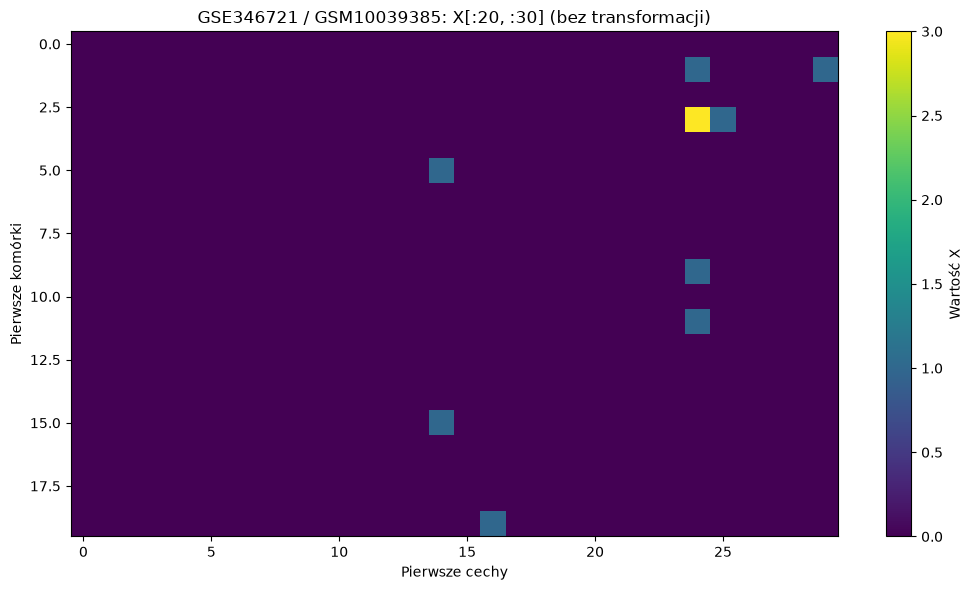


### GSE346721 / GSM10039386 — 5784 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039386:AAACCCACACGCGTCA-1,GSM10039386,AAACCCACACGCGTCA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039386:AAACCCACAGTCTGGC-1,GSM10039386,AAACCCACAGTCTGGC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039386:AAACCCACATGATCTG-1,GSM10039386,AAACCCACATGATCTG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039386:AAACGAAAGCGAACTG-1,GSM10039386,AAACGAAAGCGAACTG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039386:AAACGAACAGACTGCC-1,GSM10039386,AAACGAACAGACTGCC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039386_P34_barcodes.tsv.gz',
   'features': 'GSM10039386_P34_features.tsv.gz',
   'matrix': 'GSM10039386_P34_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

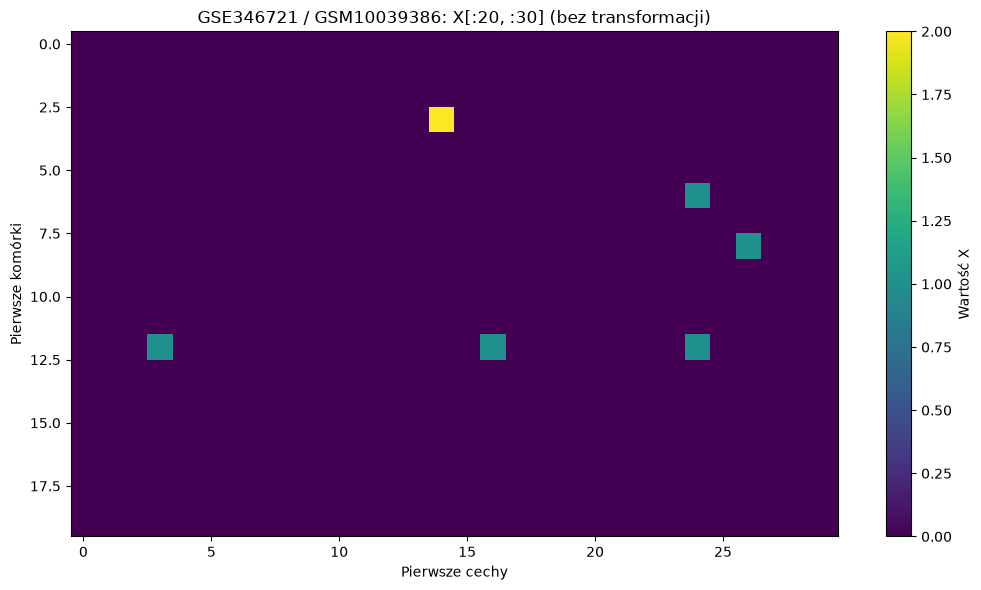


### GSE346721 / GSM10039387 — 11304 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039387:AAACCCAAGGTTAAAC-1,GSM10039387,AAACCCAAGGTTAAAC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039387:AAACCCACAACCAGAG-1,GSM10039387,AAACCCACAACCAGAG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039387:AAACCCACACGATAGG-1,GSM10039387,AAACCCACACGATAGG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039387:AAACCCACAGGTTCAT-1,GSM10039387,AAACCCACAGGTTCAT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039387:AAACCCACATGCCGAC-1,GSM10039387,AAACCCACATGCCGAC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039387_P35_barcodes.tsv.gz',
   'features': 'GSM10039387_P35_features.tsv.gz',
   'matrix': 'GSM10039387_P35_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

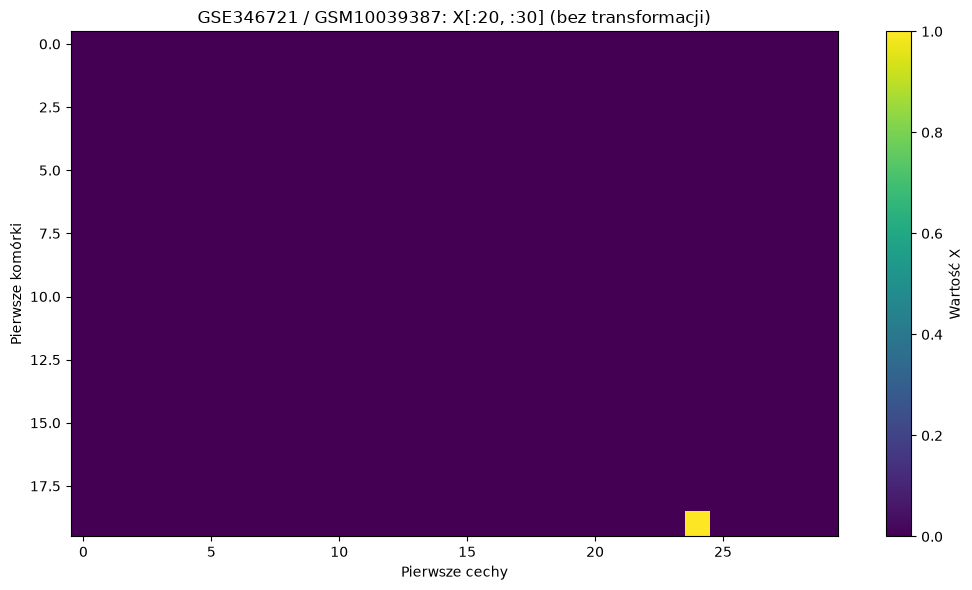


### GSE346721 / GSM10039388 — 9816 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039388:AAACCCAAGCGACATG-1,GSM10039388,AAACCCAAGCGACATG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039388:AAACCCACAAGCAGGT-1,GSM10039388,AAACCCACAAGCAGGT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039388:AAACCCACAAGTGATA-1,GSM10039388,AAACCCACAAGTGATA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039388:AAACCCACAGAAGTGC-1,GSM10039388,AAACCCACAGAAGTGC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039388:AAACCCAGTCGCAACC-1,GSM10039388,AAACCCAGTCGCAACC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039388_P36_barcodes.tsv.gz',
   'features': 'GSM10039388_P36_features.tsv.gz',
   'matrix': 'GSM10039388_P36_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

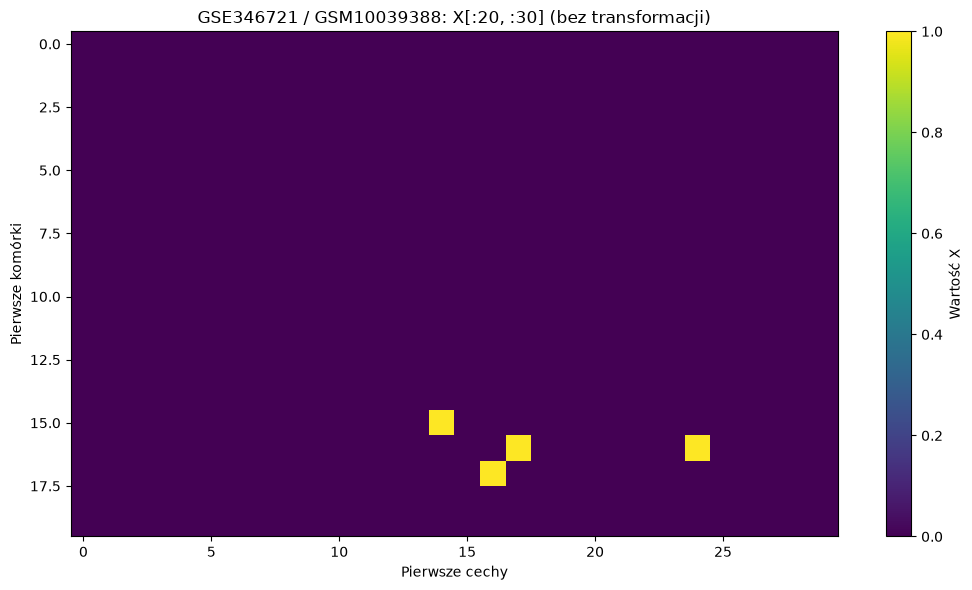


### GSE346721 / GSM10039389 — 1820 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039389:AAACCCACAGTATTCG-1,GSM10039389,AAACCCACAGTATTCG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039389:AAACCCACATGATGCT-1,GSM10039389,AAACCCACATGATGCT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039389:AAACCCAGTCGAAGCA-1,GSM10039389,AAACCCAGTCGAAGCA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039389:AAACCCATCCAGTACA-1,GSM10039389,AAACCCATCCAGTACA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039389:AAACCCATCGCCTTTG-1,GSM10039389,AAACCCATCGCCTTTG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039389_P37_barcodes.tsv.gz',
   'features': 'GSM10039389_P37_features.tsv.gz',
   'matrix': 'GSM10039389_P37_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

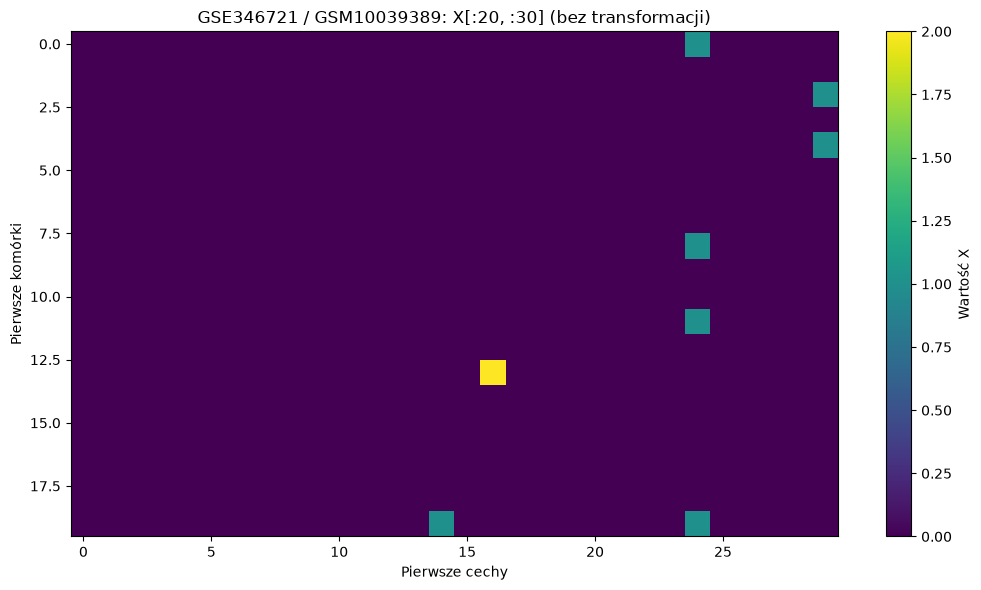


### GSE346721 / GSM10039390 — 4691 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039390:AAACCCAAGCAAGCCA-1,GSM10039390,AAACCCAAGCAAGCCA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039390:AAACCCAAGTGAGCCA-1,GSM10039390,AAACCCAAGTGAGCCA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039390:AAACCCACAACTCGAT-1,GSM10039390,AAACCCACAACTCGAT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039390:AAACCCACACTGTTCC-1,GSM10039390,AAACCCACACTGTTCC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039390:AAACCCAGTGCGGTAA-1,GSM10039390,AAACCCAGTGCGGTAA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039390_P38_barcodes.tsv.gz',
   'features': 'GSM10039390_P38_features.tsv.gz',
   'matrix': 'GSM10039390_P38_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

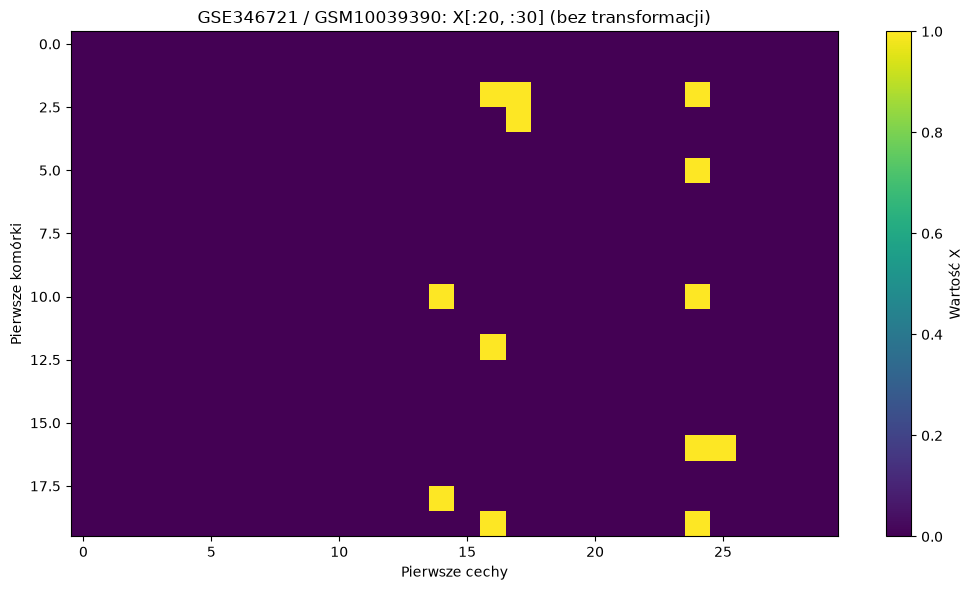


### GSE346721 / GSM10039391 — 7763 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039391:AAACCCAAGAGATTCA-1,GSM10039391,AAACCCAAGAGATTCA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039391:AAACCCAAGCGATGAC-1,GSM10039391,AAACCCAAGCGATGAC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039391:AAACCCAAGGCACGAT-1,GSM10039391,AAACCCAAGGCACGAT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039391:AAACCCAAGGGCAGTT-1,GSM10039391,AAACCCAAGGGCAGTT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039391:AAACCCACATGGGCAA-1,GSM10039391,AAACCCACATGGGCAA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039391_P39_barcodes.tsv.gz',
   'features': 'GSM10039391_P39_features.tsv.gz',
   'matrix': 'GSM10039391_P39_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

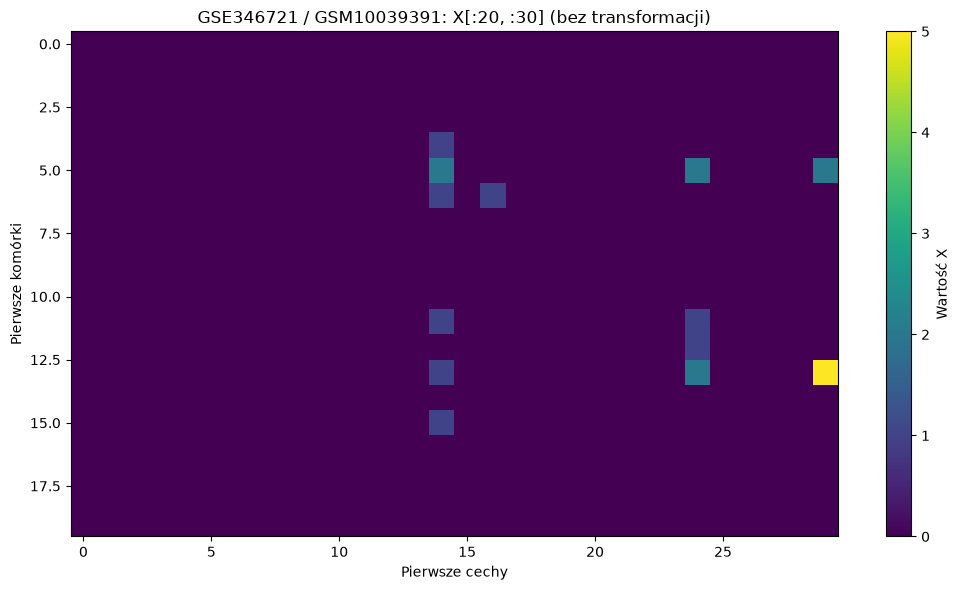


### GSE346721 / GSM10039392 — 1567 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039392:AAACCCATCGTGCAGC-1,GSM10039392,AAACCCATCGTGCAGC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039392:AAACGAACATCAGTGT-1,GSM10039392,AAACGAACATCAGTGT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039392:AAACGAAGTGTCCACG-1,GSM10039392,AAACGAAGTGTCCACG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039392:AAACGAATCATCACCC-1,GSM10039392,AAACGAATCATCACCC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039392:AAACGCTAGTATTGCC-1,GSM10039392,AAACGCTAGTATTGCC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039392_P40_barcodes.tsv.gz',
   'features': 'GSM10039392_P40_features.tsv.gz',
   'matrix': 'GSM10039392_P40_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

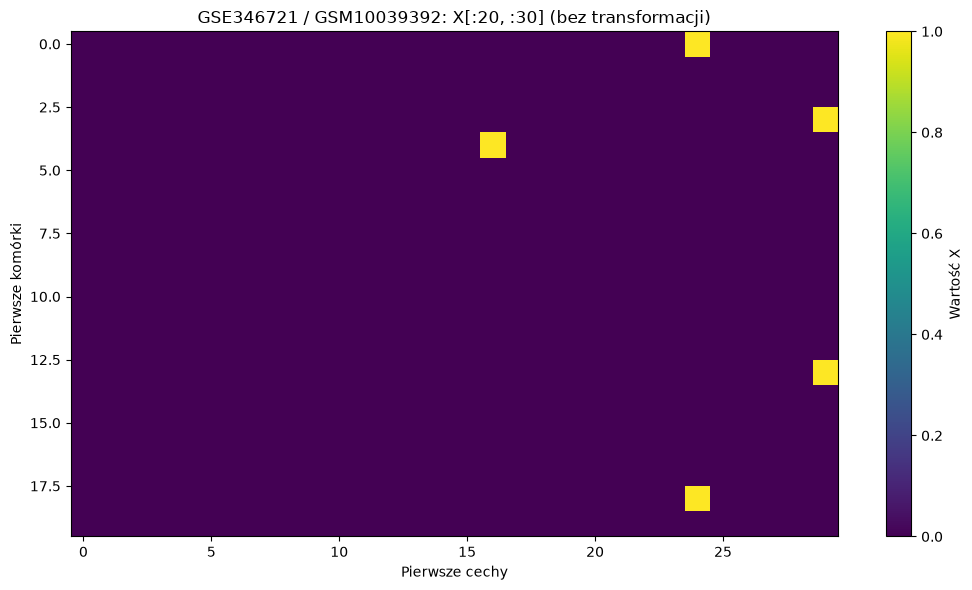


### GSE346721 / GSM10039393 — 7917 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039393:AAACCCAAGATCCCAT-1,GSM10039393,AAACCCAAGATCCCAT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039393:AAACCCAAGCCAGAGT-1,GSM10039393,AAACCCAAGCCAGAGT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039393:AAACCCACACCGCTAG-1,GSM10039393,AAACCCACACCGCTAG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039393:AAACCCACAGACCAGA-1,GSM10039393,AAACCCACAGACCAGA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039393:AAACCCAGTCATCCCT-1,GSM10039393,AAACCCAGTCATCCCT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039393_P41_barcodes.tsv.gz',
   'features': 'GSM10039393_P41_features.tsv.gz',
   'matrix': 'GSM10039393_P41_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

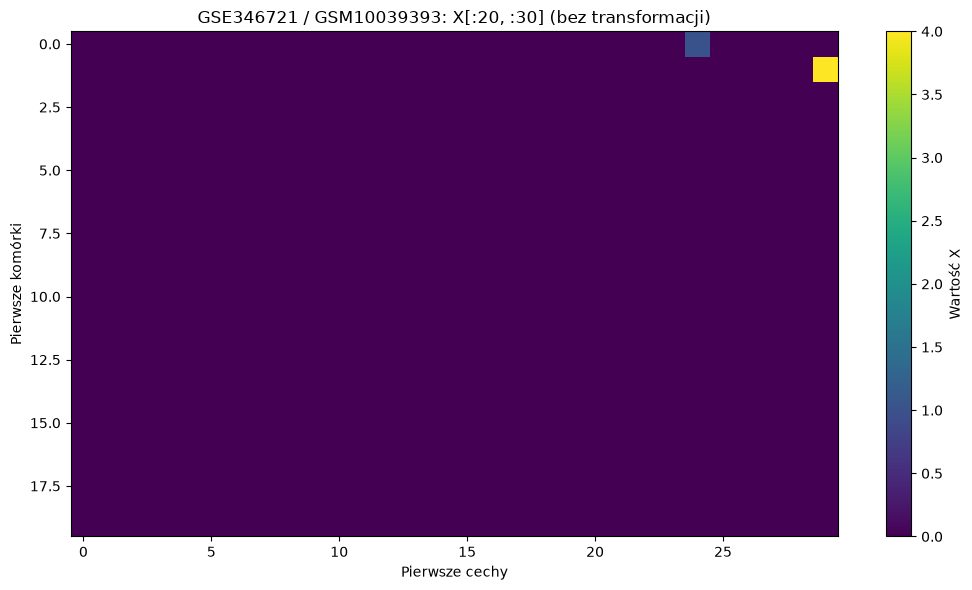


### GSE346721 / GSM10039394 — 15115 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039394:AAACCCAAGAAATCCA-1,GSM10039394,AAACCCAAGAAATCCA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039394:AAACCCAAGACGACTG-1,GSM10039394,AAACCCAAGACGACTG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039394:AAACCCAAGTATAGAC-1,GSM10039394,AAACCCAAGTATAGAC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039394:AAACCCAAGTTGCGAG-1,GSM10039394,AAACCCAAGTTGCGAG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039394:AAACCCACAACCCTAA-1,GSM10039394,AAACCCACAACCCTAA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039394_P42_barcodes.tsv.gz',
   'features': 'GSM10039394_P42_features.tsv.gz',
   'matrix': 'GSM10039394_P42_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

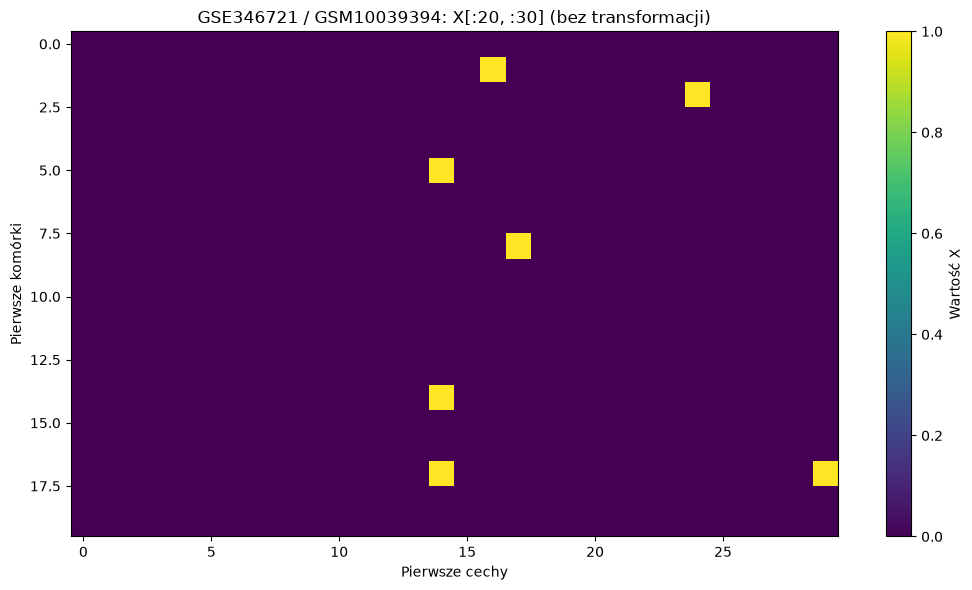


### GSE346721 / GSM10039395 — 7699 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039395:AAACCCAAGAGGACTC-1,GSM10039395,AAACCCAAGAGGACTC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039395:AAACCCAGTGATAGTA-1,GSM10039395,AAACCCAGTGATAGTA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039395:AAACCCATCGTGCAGC-1,GSM10039395,AAACCCATCGTGCAGC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039395:AAACCCATCTTCGTAT-1,GSM10039395,AAACCCATCTTCGTAT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039395:AAACGAACAAGGCGTA-1,GSM10039395,AAACGAACAAGGCGTA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039395_P43_barcodes.tsv.gz',
   'features': 'GSM10039395_P43_features.tsv.gz',
   'matrix': 'GSM10039395_P43_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

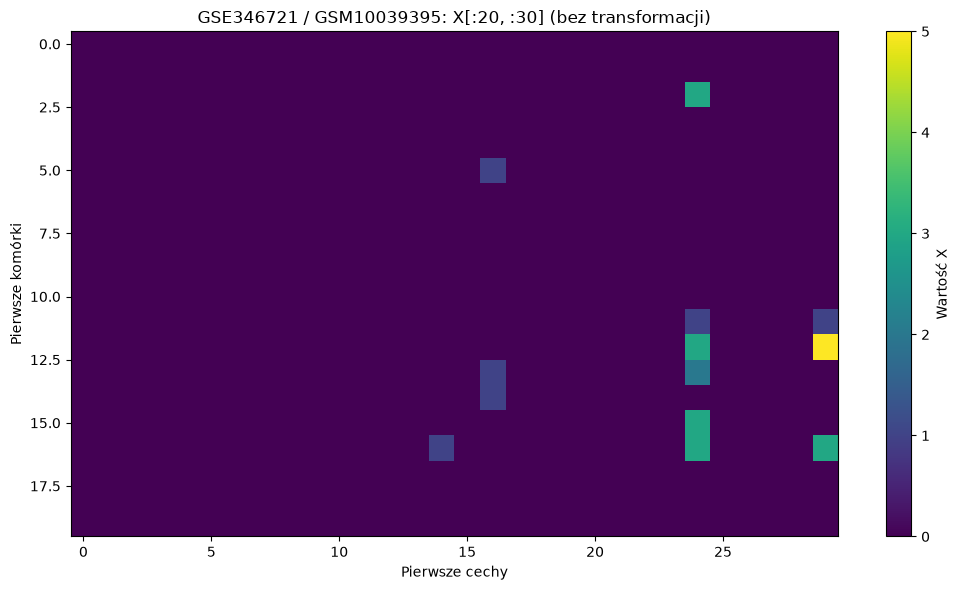


### GSE346721 / GSM10039396 — 4722 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039396:AAACCCAAGCTATCTG-1,GSM10039396,AAACCCAAGCTATCTG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039396:AAACCCAGTCTTCTAT-1,GSM10039396,AAACCCAGTCTTCTAT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039396:AAACCCAGTGCTGTCG-1,GSM10039396,AAACCCAGTGCTGTCG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039396:AAACCCAGTGGATCAG-1,GSM10039396,AAACCCAGTGGATCAG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039396:AAACCCATCTGGGTCG-1,GSM10039396,AAACCCATCTGGGTCG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039396_P44_barcodes.tsv.gz',
   'features': 'GSM10039396_P44_features.tsv.gz',
   'matrix': 'GSM10039396_P44_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

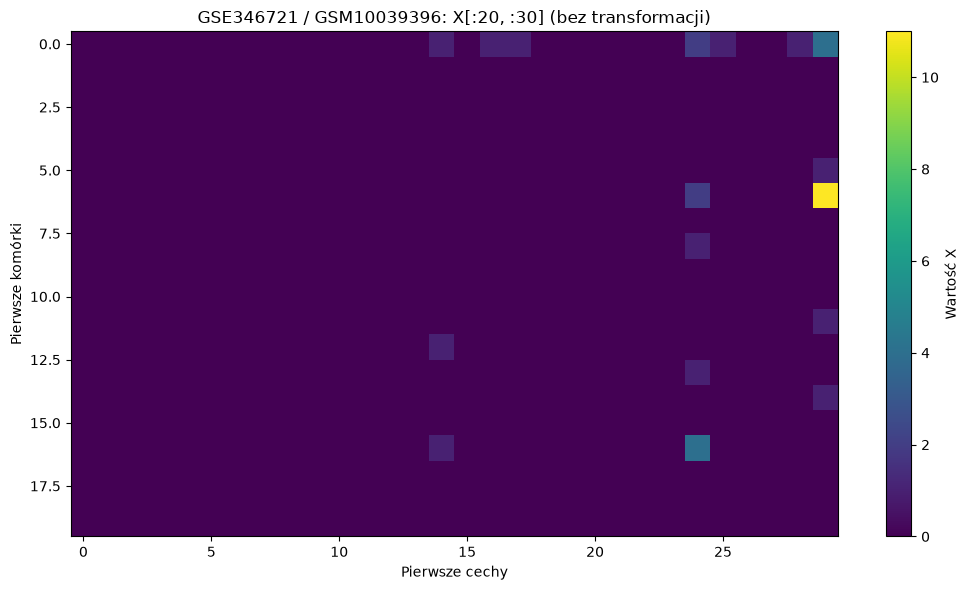


### GSE346721 / GSM10039397 — 4650 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039397:AAACCCACAAATCAAG-1,GSM10039397,AAACCCACAAATCAAG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039397:AAACCCACAACAGAGC-1,GSM10039397,AAACCCACAACAGAGC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039397:AAACCCACAGTGCCTG-1,GSM10039397,AAACCCACAGTGCCTG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039397:AAACCCATCGAGAGAC-1,GSM10039397,AAACCCATCGAGAGAC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039397:AAACGAAAGTGGGAAA-1,GSM10039397,AAACGAAAGTGGGAAA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039397_P45_barcodes.tsv.gz',
   'features': 'GSM10039397_P45_features.tsv.gz',
   'matrix': 'GSM10039397_P45_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

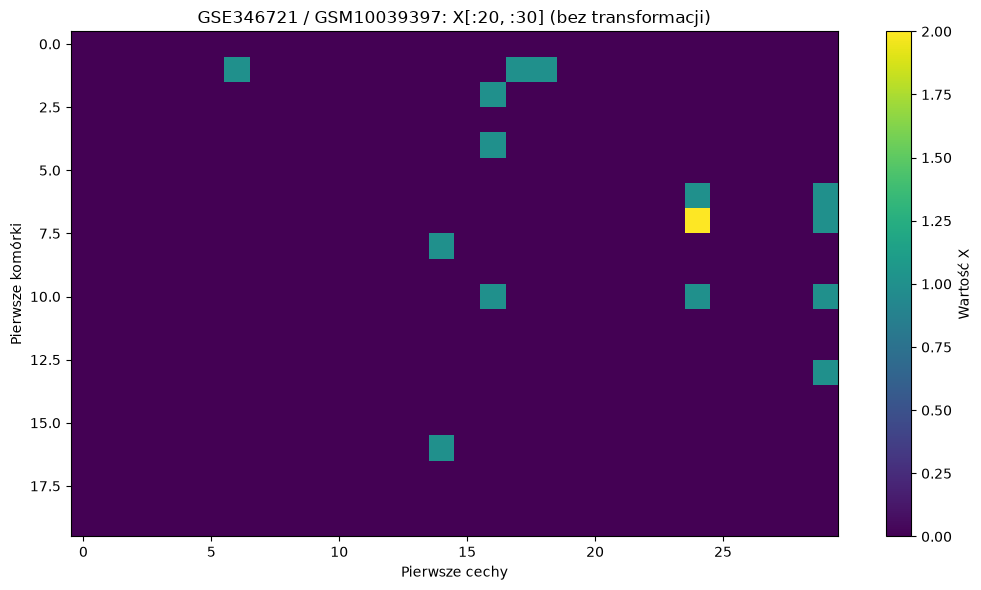


### GSE346721 / GSM10039398 — 5290 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039398:AAACCCAAGATAACGT-1,GSM10039398,AAACCCAAGATAACGT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039398:AAACCCACACATTCGA-1,GSM10039398,AAACCCACACATTCGA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039398:AAACCCATCGCTTAAG-1,GSM10039398,AAACCCATCGCTTAAG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039398:AAACGAAAGTTCGCAT-1,GSM10039398,AAACGAAAGTTCGCAT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039398:AAACGAACAAACTCGT-1,GSM10039398,AAACGAACAAACTCGT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039398_P46_barcodes.tsv.gz',
   'features': 'GSM10039398_P46_features.tsv.gz',
   'matrix': 'GSM10039398_P46_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

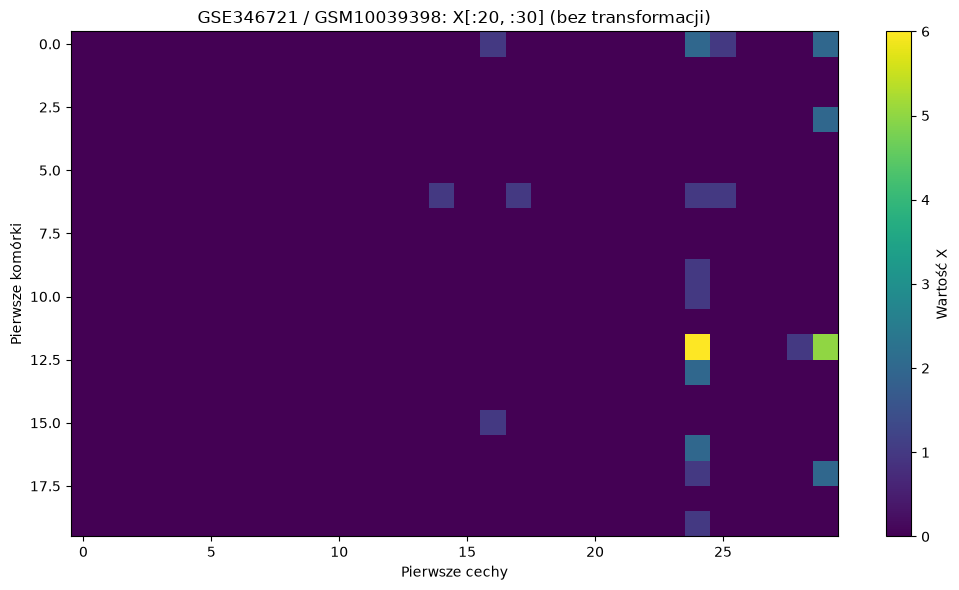


### GSE346721 / GSM10039399 — 5978 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039399:AAACCCAAGGGTAGCT-1,GSM10039399,AAACCCAAGGGTAGCT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039399:AAACCCAAGTTGGCTT-1,GSM10039399,AAACCCAAGTTGGCTT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039399:AAACCCACAAGAGTAT-1,GSM10039399,AAACCCACAAGAGTAT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039399:AAACCCACATCTGTTT-1,GSM10039399,AAACCCACATCTGTTT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039399:AAACCCAGTCGTCGGT-1,GSM10039399,AAACCCAGTCGTCGGT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039399_P47_barcodes.tsv.gz',
   'features': 'GSM10039399_P47_features.tsv.gz',
   'matrix': 'GSM10039399_P47_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

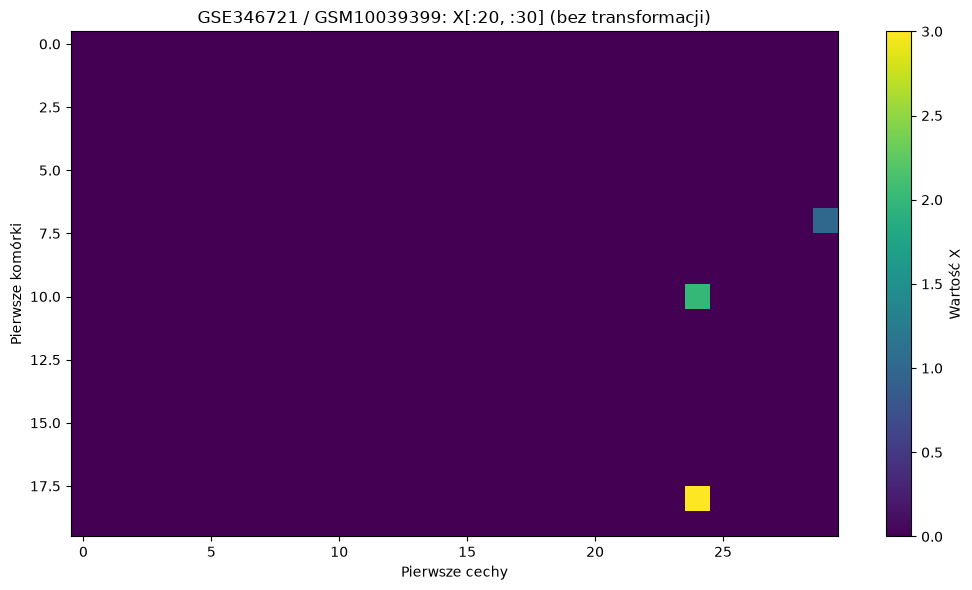


### GSE346721 / GSM10039400 — 6699 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039400:AAACCCAAGGTCGTAG-1,GSM10039400,AAACCCAAGGTCGTAG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039400:AAACCCACATAAGCGG-1,GSM10039400,AAACCCACATAAGCGG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039400:AAACCCAGTACCTAGT-1,GSM10039400,AAACCCAGTACCTAGT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039400:AAACCCAGTATTGACC-1,GSM10039400,AAACCCAGTATTGACC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039400:AAACGAAAGAAGCGGG-1,GSM10039400,AAACGAAAGAAGCGGG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039400_P48_barcodes.tsv.gz',
   'features': 'GSM10039400_P48_features.tsv.gz',
   'matrix': 'GSM10039400_P48_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

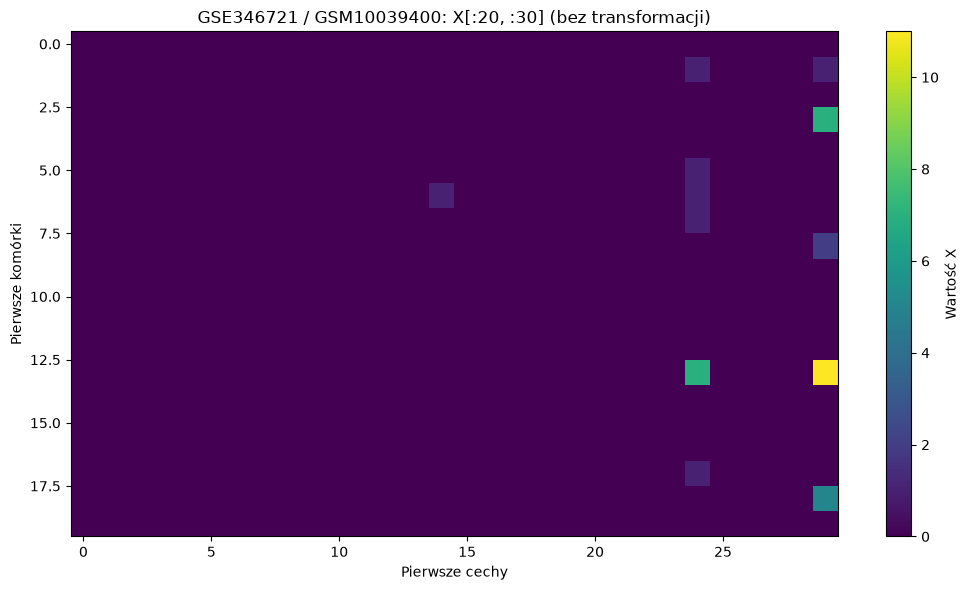


### GSE346721 / GSM10039401 — 6782 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039401:AAACCCACATTCTCCG-1,GSM10039401,AAACCCACATTCTCCG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039401:AAACCCAGTAGGAAAG-1,GSM10039401,AAACCCAGTAGGAAAG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039401:AAACCCAGTTCTCGTC-1,GSM10039401,AAACCCAGTTCTCGTC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039401:AAACCCATCAGAGTGG-1,GSM10039401,AAACCCATCAGAGTGG-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039401:AAACCCATCATTACCT-1,GSM10039401,AAACCCATCATTACCT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039401_P49_barcodes.tsv.gz',
   'features': 'GSM10039401_P49_features.tsv.gz',
   'matrix': 'GSM10039401_P49_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

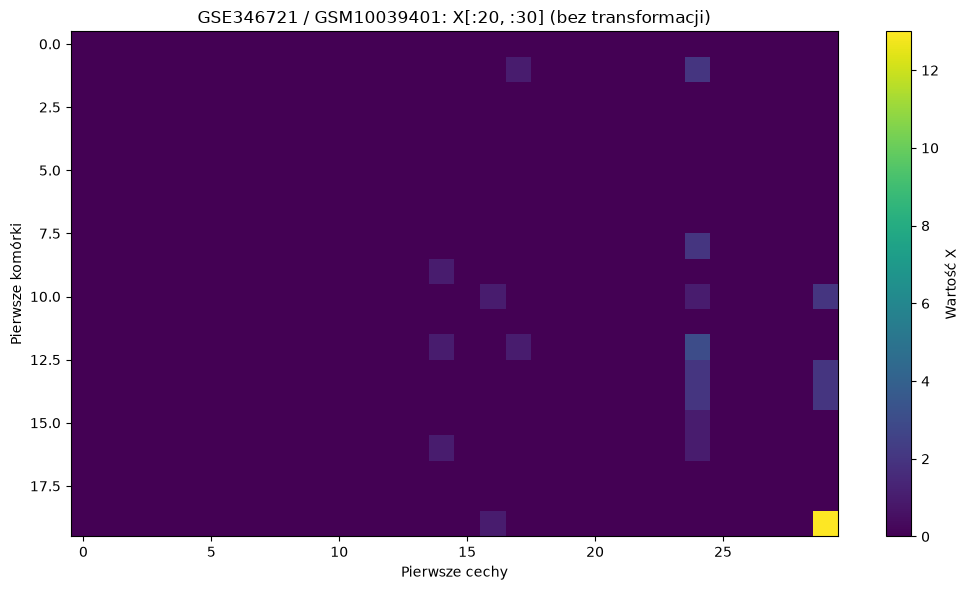


### GSE346721 / GSM10039402 — 9632 komórek × 36601 cech
obs.head():


,sample_id,source_barcode,donor_id,organism,tissue,cell_type,disease,condition,assay,modality,timepoint,source_accession,n_counts,n_features,percent_mito
cell_id,,,,,,,,,,,,,,,
GSM10039402:AAACCCAAGATACGAT-1,GSM10039402,AAACCCAAGATACGAT-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039402:AAACCCAAGATGGCAC-1,GSM10039402,AAACCCAAGATGGCAC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039402:AAACCCAAGCCAACCC-1,GSM10039402,AAACCCAAGCCAACCC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039402:AAACCCAAGGTGCCAA-1,GSM10039402,AAACCCAAGGTGCCAA-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN
GSM10039402:AAACCCAAGTGCTCGC-1,GSM10039402,AAACCCAAGTGCTCGC-1,<NA>,Homo sapiens,Rectum mucosal tissue,<NA>,Crohn's disease with perianal fistula,Crohn's disease with perianal fistula,<NA>,<NA>,<NA>,GSE346721,<NA>,<NA>,NaN


var.head():


,feature_name,feature_type,genome_build
feature_id,,,
ENSG00000243485,MIR1302-2HG,Gene Expression,<NA>
ENSG00000237613,FAM138A,Gene Expression,<NA>
ENSG00000186092,OR4F5,Gene Expression,<NA>
ENSG00000238009,AL627309.1,Gene Expression,<NA>
ENSG00000239945,AL627309.3,Gene Expression,<NA>


uns:


{'schema_version': '1.1',
 'source_gse': 'GSE346721',
 'source_format': {'components': {'barcodes': 'GSM10039402_P50_barcodes.tsv.gz',
   'features': 'GSM10039402_P50_features.tsv.gz',
   'matrix': 'GSM10039402_P50_matrix.mtx.gz'},
  'file': 'GSE346721_RAW.tar',
  'format': '10x Matrix Market',
  'source_sha256': 'a500ad10c453efffbc4975a5c561652fb6e8dfa9f295d07d331bf807253a1697'},
 'matrix_semantics': 'unknown',
 'feature_id_namespace': 'unknown',
 'harmonization_notes': 'Loaded without normalization; matrix semantics and feature namespace were not confirmed by source documentation.'}

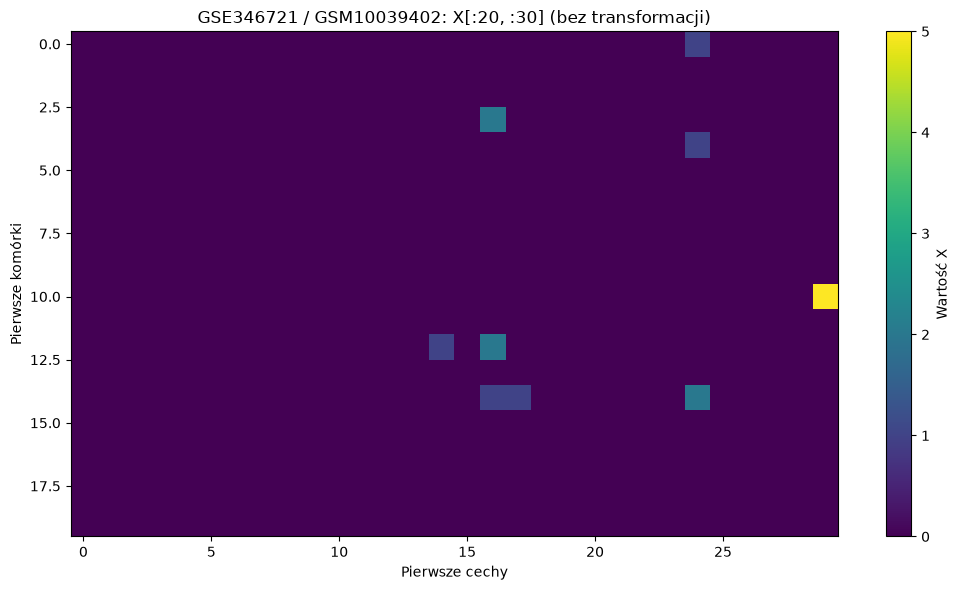

In [6]:
for (gse, gsm), adata in objects.items():
    print(f'\n### {gse} / {gsm} — {adata.n_obs} komórek × {adata.n_vars} cech')
    print('obs.head():')
    display(adata.obs.head())
    print('var.head():')
    display(adata.var.head())
    print('uns:')
    display({key: adata.uns.get(key) for key in [
        'schema_version', 'source_gse', 'source_format', 'matrix_semantics',
        'feature_id_namespace', 'harmonization_notes'
    ]})
    n = min(MAX_PREVIEW_CELLS, adata.n_obs)
    p = min(MAX_PREVIEW_FEATURES, adata.n_vars)
    if n and p:
        view = adata.X[:n, :p]
        if sparse.issparse(view):
            view = view.toarray()
        fig, ax = plt.subplots(figsize=(min(12, 3 + p * 0.25), min(6, 2 + n * 0.2)))
        im = ax.imshow(view, aspect='auto', interpolation='nearest')
        ax.set_title(f'{gse} / {gsm}: X[:{n}, :{p}] (bez transformacji)')
        ax.set_xlabel('Pierwsze cechy')
        ax.set_ylabel('Pierwsze komórki')
        fig.colorbar(im, ax=ax, label='Wartość X')
        plt.tight_layout()
        plt.show()


## Podsumowanie do ręcznego przeglądu

Zwróć uwagę na próbki bez obiektu, niepuste pola metadanych, unikalność indeksów, wymiary macierzy i semantykę `X`. `cell_type` powinno pozostać puste przed krokiem anotacji. Ten notebook pokazuje zawartość i nie potwierdza biologicznej poprawności ani semantyki, których nie potwierdził import.
